# Fase 2 — Caricamento dei dati e analisi esplorativa

In [1]:
import numpy as np
from helpers import load_csv_data

DATA_PATH = "dataset/"

x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)

In [2]:
print(f"x_train: {x_train.shape} | x_test: {x_test.shape} | y_train: {y_train.shape}")

values, counts = np.unique(y_train, return_counts=True)
print(f"Labels: {values} | Proportions: {counts / len(y_train)}")

# Trivial baselines
p = np.mean(y_train == 1)   # positive-class prevalence
print(f"p = {p:.4f} | acc always-negative = {1 - p:.4f} | F1 always-positive = {2*p/(1+p):.4f}")

x_train: (328135, 321) | x_test: (109379, 321) | y_train: (328135,)
Labels: [-1  1] | Proportions: [0.91169793 0.08830207]
p = 0.0883 | acc always-negative = 0.9117 | F1 always-positive = 0.1623


## Dimensioni ed etichette

- Training: 328 135 individui × 321 feature. Test: 109 379 individui.
- Etichette in $\{-1, +1\}$. Per la regressione logistica serve $y \in \{0,1\}$: useremo $y_{01} = (y+1)/2$
  e la mappa inversa per la submission.
- **Forte sbilanciamento:** prevalenza dei positivi $p = 0.0883$.

| Classificatore banale | Accuracy | F1 |
|---|---|---|
| Sempre negativo | 0.912 | 0 |
| Sempre positivo | 0.088 | $2p/(1+p) = 0.162$ |

**Conseguenza:** l'accuracy da sola è fuorviante, perché il 91% si ottiene senza imparare nulla.
La metrica principale sarà l'F1, e la soglia di classificazione andrà ottimizzata invece di fissarla a 0.5.

In [3]:
with open(DATA_PATH + "x_train.csv") as f:
    col_names = np.array(f.readline().strip().split(",")[1:])   # drop 'Id'

col_idx = {name: j for j, name in enumerate(col_names)}   # name -> column index

## Colonne da escludere a priori (codebook [1])

- **Target:** `_MICHD` vale 1 se `CVDINFR4 = 1` (infarto) oppure `CVDCRHD4 = 1` (angina o coronaropatia) [1].
  Nessuna delle due variabili è presente nel dataset.
- **Amministrative:** date e identificativi, modalità telefonica e residenza, versione e lingua del
  questionario, pesi e strati di survey. Descrivono il processo di intervista e il disegno campionario,
  non la salute dell'individuo.
- **Ridondanti:** molte variabili calcolate sono funzioni documentate di altre colonne [1]. Una variabile
  viene esclusa quando è (quasi) una combinazione lineare di feature già presenti nel modello:
  conversioni di unità (`WEIGHT2` → `WTKG3`), frequenze convertite (`FRUIT1` → `FRUTDA1_`), raggruppamenti
  di variabili codificate one-hot (`_RFHYPE5` da `BPHIGH4`), duplicati della stessa domanda
  (`_DRDXAR1` = `HAVARTH3`), variabili ricostruibili dalle dummy di un'altra (`SMOKE100` = 2 se e solo se
  `_SMOKER3` = 4). Si tengono invece le soglie su variabili numeriche (es. `_RFHLTH` =
  `GENHLTH` ≥ 4), che aggiungono al modello lineare una non linearità.
- `_STATE` (stato di residenza, 53 livelli) è valutata in cross-validation (4.4) e poi esclusa.

L'elenco completo è nella cella 4.1.

In [4]:
# Fraction of NaN per column
nan_train = np.isnan(x_train).mean(axis=0)
nan_test = np.isnan(x_test).mean(axis=0)

# 40 emptiest columns, train vs test
order = np.argsort(nan_train)[::-1]
print(f"{'column':<12} {'train':>6} {'test':>6}")
for j in order[:40]:
    print(f"{col_names[j]:<12} {nan_train[j]:>6.3f} {nan_test[j]:>6.3f}")

column        train   test
LADULT        1.000  1.000
COLGHOUS      1.000  1.000
PCDMDECN      0.999  0.999
ASDRVIST      0.999  0.999
ASERVIST      0.999  0.999
ASNOSLEP      0.999  0.999
ASINHALR      0.999  0.999
ASTHMED3      0.999  0.999
ASYMPTOM      0.999  0.999
ASACTLIM      0.999  0.999
ASRCHKUP      0.999  0.999
ASATTACK      0.999  0.999
STREHAB1      0.998  0.999
PCPSADE1      0.998  0.998
HAREHAB1      0.998  0.998
ASTHMAGE      0.998  0.998
VINOCRE2      0.998  0.998
CCLGHOUS      0.998  0.998
HPVADSHT      0.997  0.997
VIEYEXM2      0.994  0.994
VIMACDG2      0.993  0.993
VIGLUMA2      0.993  0.993
VICTRCT4      0.993  0.993
VIINSUR2      0.993  0.993
VIPRFVS2      0.993  0.993
VIREDIF3      0.993  0.993
VIDFCLT2      0.993  0.993
PCPSARS1      0.992  0.991
PSATIME       0.992  0.991
CDHELP        0.991  0.990
LENGEXAM      0.989  0.989
RDUCSTRK      0.987  0.988
RLIVPAIN      0.987  0.988
RDUCHART      0.987  0.988
PROFEXAM      0.987  0.987
CASTHNO2      0.985  0.985
P

In [5]:
# Number of columns above each missingness threshold
for tau in [0.0, 0.1, 0.3, 0.5, 0.8, 0.95]:
    print(f"Columns with > {tau:.0%} NaN: {np.sum(nan_train > tau)}")

Columns with > 0% NaN: 239
Columns with > 10% NaN: 182
Columns with > 30% NaN: 177
Columns with > 50% NaN: 147
Columns with > 80% NaN: 116
Columns with > 95% NaN: 68


In [6]:
# Fraction of NaN per row
nan_rows = np.isnan(x_train).mean(axis=1)
print(f"NaN per row -> min: {nan_rows.min():.3f} | median: {np.median(nan_rows):.3f} | max: {nan_rows.max():.3f}")

NaN per row -> min: 0.249 | median: 0.433 | max: 0.679


In [7]:
# Largest train/test gap in missingness (distribution shift check)
diff = np.abs(nan_train - nan_test)
print(f"Max train/test NaN gap: {diff.max():.3f} in column {col_names[np.argmax(diff)]}")

Max train/test NaN gap: 0.004 in column HHADULT


## Valori mancanti

| Frazione di NaN | > 0 | > 10% | > 30% | > 50% | > 80% | > 95% |
|---|---|---|---|---|---|---|
| Colonne (su 321) | 239 | 182 | 177 | 147 | 116 | 68 |

- **Per riga:** ogni individuo ha almeno il 25% di valori mancanti (mediana 43%). Eliminare le righe
  incomplete svuoterebbe il dataset: la mancanza va gestita **per colonne** (soglia $\tau$, imputazione,
  indicatori di mancanza, Fase 4).
- **Train contro test:** lo scarto massimo nella frazione di NaN è 0.004 (`HHADULT`). Il meccanismo di
  mancanza è lo stesso nei due insiemi, quindi un preprocessing appreso sul training è applicabile al test.
- La maggior parte dei NaN non è casuale: viene dagli *skip pattern* del questionario, cioè da domande
  poste solo a un sottogruppo (ad esempio i farmaci per la pressione solo agli ipertesi). La mancanza è
  quindi informativa, e va controllato che non riveli il target (cella seguente).

In [8]:
# HAREHAB1 is asked only if CVDINFR4 = 1 (codebook): positive rate among respondents
answered = ~np.isnan(x_train[:, col_idx["HAREHAB1"]])
print(f"HAREHAB1 answered: {answered.sum()} | positive rate among answered: {np.mean(y_train[answered] == 1):.3f}")

HAREHAB1 answered: 773 | positive rate among answered: 1.000


## Leakage attraverso gli skip pattern

Per ogni domanda il codebook [1] riporta le condizioni per cui non viene posta ("BLANK: Not asked or
Missing"). Cercando in queste note le variabili che definiscono il target (`CVDINFR4`, `CVDCRHD4`) compare
una sola domanda: `HAREHAB1` (riabilitazione dopo l'infarto), non posta se `CVDINFR4` è 2, 7, 9 o mancante.
Quindi $\text{HAREHAB1} \neq \text{NaN} \Rightarrow \texttt{CVDINFR4} = 1 \Rightarrow \texttt{\_MICHD} = 1$.

**Verifica sui dati:** 773 rispondenti, tutti positivi (tasso 1.000 contro $p = 0.088$).
Il target è codificato dal *pattern di mancanza*, non dal valore, e riguarda circa il 2.7% dei positivi.
**Scelta: `HAREHAB1` esclusa**, incluso ogni suo indicatore di mancanza.

Gli altri skip pattern dipendono da caratteristiche legittime: ad esempio `STREHAB1` dall'ictus, il modulo
cognitivo dall'età ≥ 45, il modulo sul diabete da `DIABETE3`, le domande sul vaccino HPV dall'età ≤ 49.
In questi casi il pattern di mancanza è informativo, ma non è leakage.

In [9]:
# Per-column profile: missing fraction, distinct values, integer-valued, range
n_unique = np.array([len(np.unique(c[~np.isnan(c)])) for c in x_train.T])
is_int = np.array([np.all(c[~np.isnan(c)] % 1 == 0) for c in x_train.T])
col_min = np.nanmin(x_train, axis=0)
col_max = np.nanmax(x_train, axis=0)

print(f"{'column':<10} {'NaN':>5} {'uniq':>6} {'int':>5} {'min':>10} {'max':>10}")
for j in range(x_train.shape[1]):
    print(f"{col_names[j]:<10} {nan_train[j]:>5.2f} {n_unique[j]:>6} {str(is_int[j]):>5} "
          f"{col_min[j]:>10.2f} {col_max[j]:>10.2f}")

column       NaN   uniq   int        min        max
_STATE      0.00     53  True       1.00      72.00
FMONTH      0.00     12  True       1.00      12.00
IDATE       0.00    414  True 1012016.00 12312015.00
IMONTH      0.00     12  True       1.00      12.00
IDAY        0.00     31  True       1.00      31.00
IYEAR       0.00      2  True    2015.00    2016.00
DISPCODE    0.00      2  True    1100.00    1200.00
SEQNO       0.00  21780  True 2015000001.00 2015023235.00
_PSU        0.00  21780  True 2015000001.00 2015023235.00
CTELENUM    0.42      1  True       1.00       1.00
PVTRESD1    0.42      2  True       1.00       2.00
COLGHOUS    1.00      1  True       1.00       1.00
STATERES    0.42      1  True       1.00       1.00
CELLFON3    0.42      2  True       1.00       2.00
LADULT      1.00      2  True       1.00       2.00
NUMADULT    0.42     16  True       1.00      20.00
NUMMEN      0.43     12  True       0.00      18.00
NUMWOMEN    0.43     11  True       0.00      10.00

## 2.5 Profilo delle colonne

Per ogni feature: frazione di NaN, numero di valori distinti, se è intera, minimo e massimo.
Quasi tutte le colonne sono intere con pochi valori: il dataset è in gran parte categorico o ordinale.
Il significato dei codici è nel codebook [1]. Le convenzioni principali:

| Famiglia | Esempi | Codici speciali |
|---|---|---|
| Sì/No, scale brevi | `CVDSTRK3`, `GENHLTH` | 7 = non so, 9 = rifiutato |
| Giorni, conteggi | `PHYSHLTH`, `AVEDRNK2` | 77 = non so, 88 = nessuno (→ 0), 99 = rifiutato |
| Frequenze composte | `ALCDAY5`, `FRUIT1` | 1xx/2xx/3xx = per giorno/settimana/mese; 555/888 = mai; 777, 999 |
| Calcolate categoriche | `_RFHYPE5`, `_SMOKER3` | 9 = non so/rifiutato/mancante |

Il profilo serve a verificare le **trasformazioni applicate nel dataset del corso** rispetto al file CDC
descritto dal codebook:
- i decimali impliciti sono già applicati (`_BMI5` ∈ [12, 98], `WTKG3` in kg, `HTM4` in m);
- i valori "BLANK" sono NaN; alcuni codici di mancanza sono già NaN (es. 99999 di `WTKG3`), altri sono
  solo riscalati (99900 → 999 in `MAXVO2_`, 99000 → 99 in `STRFREQ_`).

Nelle variabili `_RF...` la codifica è 1 = no, 2 = sì, opposta a quella delle domande grezze (1 = sì).

**Conseguenza:** i codici vanno ricodificati (Fase 4), verificandoli sia sul codebook sia sui dati.

In [10]:
def positive_rate_by_value(name, max_valid):
    """Print the positive rate and sample size for each valid value of a column."""
    col = x_train[:, col_idx[name]]
    parts = []
    for v in np.unique(col[col <= max_valid]):
        mask = col == v
        parts.append(f"{v:g}: {np.mean(y_train[mask] == 1):.3f} (n={mask.sum()})")
    print(f"{name} -> " + " | ".join(parts))

# Key clinical and demographic variables, with their largest valid code
for name, max_valid in [("_AGEG5YR", 13), ("SEX", 2), ("GENHLTH", 5), ("_RFHYPE5", 2),
                        ("_RFCHOL", 2), ("DIABETE3", 4), ("CVDSTRK3", 2), ("_SMOKER3", 4)]:
    positive_rate_by_value(name, max_valid)

_AGEG5YR -> 1: 0.005 (n=18145) | 2: 0.009 (n=14686) | 3: 0.011 (n=17122) | 4: 0.015 (n=18308) | 5: 0.023 (n=19296) | 6: 0.037 (n=22539) | 7: 0.056 (n=29693) | 8: 0.072 (n=34379) | 9: 0.100 (n=37210) | 10: 0.123 (n=36665) | 11: 0.161 (n=28190) | 12: 0.185 (n=20893) | 13: 0.222 (n=27066)
SEX -> 1: 0.112 (n=138783) | 2: 0.071 (n=189352)
GENHLTH -> 1: 0.021 (n=56937) | 2: 0.042 (n=108089) | 3: 0.091 (n=101880) | 4: 0.193 (n=43349) | 5: 0.319 (n=16992)
_RFHYPE5 -> 1: 0.038 (n=195416) | 2: 0.163 (n=131801)
_RFCHOL -> 1: 0.052 (n=163056) | 2: 0.161 (n=118755)
DIABETE3 -> 1: 0.221 (n=42223) | 2: 0.040 (n=2675) | 3: 0.067 (n=277049) | 4: 0.145 (n=5709)
CVDSTRK3 -> 1: 0.371 (n=13366) | 2: 0.076 (n=314032)
_SMOKER3 -> 1: 0.104 (n=32444) | 2: 0.098 (n=13230) | 3: 0.135 (n=90838) | 4: 0.062 (n=178357)


### Associazione univariata con il target

Tasso di positivi per valore (significato dei codici dal codebook [1]; $p = 0.088$):

| Variabile | Risultato |
|---|---|
| Età (`_AGEG5YR`, 1 = 18–24 … 13 = 80+) | cresce in modo monotono da 0.005 a 0.222 (≈ 44×): **fattore più forte** |
| Sesso (`SEX`, 1 = M, 2 = F) | 0.112 vs 0.071 |
| Salute percepita (`GENHLTH`, 1 = eccellente … 5 = scarsa) | monotona, da 0.021 a 0.319 |
| Ipertensione (`_RFHYPE5`, 1 = no, 2 = sì) | 0.038 vs 0.163 |
| Colesterolo alto (`_RFCHOL`, 1 = no, 2 = sì) | 0.052 vs 0.161 |
| Ictus (`CVDSTRK3`, 1 = sì, 2 = no) | 0.371 vs 0.076 |

**Osservazioni:**
- **Età.** La crescita è fortemente non lineare sulla scala delle probabilità, ma circa lineare sulla scala
  logit ($\log\frac{r}{1-r}$ passa da −5.3 a −1.3 con incrementi quasi costanti). Il modello logistico è
  quindi più adatto dei modelli MSE, che lavorano sulla scala delle probabilità.
- **`DIABETE3` non è ordinale:** 1 = diabete (0.221), 2 = solo in gravidanza (0.040), 3 = no (0.067),
  4 = prediabete (0.145). L'ordine del rischio (2 < 3 < 4 < 1) non segue quello dei codici, quindi va
  trattata con one-hot encoding.
- **`_SMOKER3` non è monotona:** 1 = fumatore quotidiano (0.104), 2 = occasionale (0.098),
  3 = ex fumatore (0.135), 4 = mai (0.062). Gli ex fumatori hanno il tasso più alto. Spiegazioni
  plausibili: sono mediamente più anziani (confondimento da età), e il target è una diagnosi *lifetime*,
  quindi molti potrebbero aver smesso **dopo** la diagnosi (causalità inversa). Anche questa va trattata
  con one-hot.
- Queste associazioni sono **marginali**: non tengono conto delle correlazioni tra fattori (es. età e
  ipertensione). Per un compito predittivo va bene, ma non vanno interpretate come effetti causali.

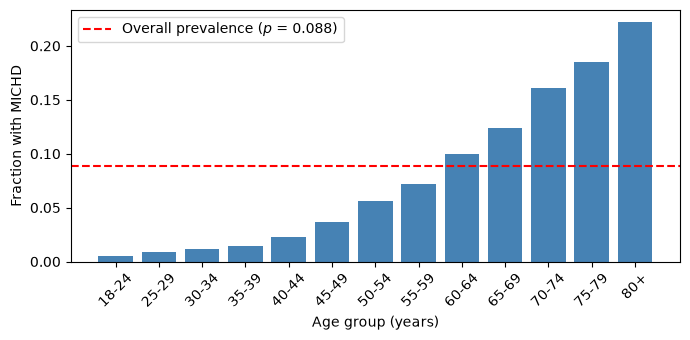

In [11]:
import matplotlib.pyplot as plt

# Positive rate by 5-year age group (_AGEG5YR: 1 = 18-24, ..., 13 = 80+)
age = x_train[:, col_idx["_AGEG5YR"]]
groups = np.arange(1, 14)
rates = [np.mean(y_train[age == g] == 1) for g in groups]
labels = ["18-24"] + [f"{25 + 5*i}-{29 + 5*i}" for i in range(11)] + ["80+"]

plt.figure(figsize=(7, 3.5))
plt.bar(labels, rates, color="steelblue")
plt.axhline(p, color="red", linestyle="--", label=f"Overall prevalence ($p$ = {p:.3f})")
plt.xlabel("Age group (years)")
plt.ylabel("Fraction with MICHD")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("figures/positive_rate_by_age.pdf")
plt.show()

**Figura 1** (`figures/positive_rate_by_age.pdf`): tasso di positivi per fascia d'età di 5 anni; la linea
tratteggiata è la prevalenza complessiva $p = 0.088$. Il tasso cresce in modo monotono e supera $p$ a
partire dai 60 anni.

## Riepilogo della Fase 2 e decisioni per il preprocessing

**Problema**
- Classificazione binaria fortemente sbilanciata ($p = 0.088$). Metrica principale: F1.
  La soglia di classificazione verrà ottimizzata.
- Etichette $\{-1,+1\}$ → $\{0,1\}$ per l'addestramento, mappa inversa per la submission.

**Colonne escluse** (elenco nella cella 4.1)
- Amministrative, leakage (`HAREHAB1`), ridondanti secondo le definizioni del codebook, date.

**Ricodifica**
- "Non so" / "rifiutato" (7, 77, 777, 9, 99, 999, …) → NaN; "nessuno" / "mai" (88, 555, 888) → 0.
- Eccezioni verificate sul codebook per le colonne che possono entrare nel modello.

**Trattamento delle feature**
- Colonne con frazione di NaN $> \tau$ eliminate, con $\tau$ scelta in cross-validation.
- Imputazione con la mediana più indicatori di mancanza, perché il pattern di mancanza è informativo.
- One-hot encoding per le variabili nominali o ordinali non monotone.
- Standardizzazione; winsorizzazione delle variabili continue da valutare in CV.

**Principio generale:** tutte le statistiche di preprocessing vengono calcolate **solo sui dati di
training** di ogni fold, per evitare data leakage.

# Fase 3 — Protocollo di validazione

Obiettivo: strumenti per valutare in modo onesto ogni scelta di preprocessing e di modello.
Internamente le etichette sono in $\{0,1\}$.

## 3.1 Metriche

Tutte le metriche derivano dalla matrice di confusione (TP, FP, FN, TN). Per l'F1 usiamo la forma
equivalente alla media armonica di precision e recall:
$$F_1 = \frac{2PR}{P+R} = \frac{2\,TP}{2\,TP + FP + FN},$$
che resta definita anche quando il modello non predice alcun positivo ($TP + FP = 0$).

**Verifica:** le funzioni riproducono i valori analitici del passo 2.3 (accuracy 0.9117 e F1 = 0 per
"sempre negativo"; F1 = 0.1623 per "sempre positivo").

In [12]:
from implementations import logistic_regression
from validation import (SEED, accuracy, f1_score, auc_score, stratified_kfold_indices,
                        cross_validate, print_cv, corrected_se)

K = 5


def sigmoid(t):
    """Logistic function."""
    return 1 / (1 + np.exp(-t))

In [13]:
# Map labels from {-1, 1} to {0, 1}
y01 = ((y_train + 1) / 2).astype(int)

always_neg = np.zeros_like(y01)
always_pos = np.ones_like(y01)

print(f"Always negative -> accuracy: {accuracy(y01, always_neg):.4f} | F1: {f1_score(y01, always_neg):.4f}")
print(f"Always positive -> accuracy: {accuracy(y01, always_pos):.4f} | F1: {f1_score(y01, always_pos):.4f}")

Always negative -> accuracy: 0.9117 | F1: 0.0000
Always positive -> accuracy: 0.0883 | F1: 0.1623


In [14]:
rng = np.random.default_rng(0)

print(f"Constant scores -> AUC: {auc_score(y01, np.zeros(len(y01))):.4f}   (expected 0.5)")
print(f"Perfect scores  -> AUC: {auc_score(y01, y01.astype(float)):.4f}   (expected 1.0)")
print(f"Random scores   -> AUC: {auc_score(y01, rng.random(len(y01))):.4f}   (expected ~0.5)")
print(f"Age alone       -> AUC: {auc_score(y01, x_train[:, col_idx['_AGE80']]):.4f}")

Constant scores -> AUC: 0.5000   (expected 0.5)
Perfect scores  -> AUC: 1.0000   (expected 1.0)
Random scores   -> AUC: 0.5020   (expected ~0.5)
Age alone       -> AUC: 0.7369


## 3.2 AUC

L'AUC misura la qualità del *ranking* dei punteggi, indipendentemente dalla soglia:
$\text{AUC} = P(S^+ > S^-) + \tfrac12 P(S^+ = S^-)$. La calcoliamo con la statistica di Mann–Whitney
(ranghi medi per gli ex aequo), in $O(n \log n)$.

**Verifica:**
- punteggi costanti → 0.5000 e punteggi perfetti → 1.0000, come atteso;
- punteggi casuali → 0.5020. Sotto l'ipotesi di punteggi casuali, la deviazione standard dell'AUC è
  $\sqrt{\frac{n^+ + n^- + 1}{12\, n^+ n^-}} \approx 0.0018$, quindi lo scarto osservato è di circa
  1.1 deviazioni standard: compatibile con il caso.

**Risultato:** l'età da sola (`_AGE80`) raggiunge **AUC = 0.737**. È un riferimento importante: un modello
multivariato deve superare nettamente questo valore per giustificare la sua complessità.

In [15]:
folds = stratified_kfold_indices(y01, K, SEED)

for i, f in enumerate(folds):
    print(f"Fold {i}: size {len(f)} | positive rate {y01[f].mean():.4f}")

all_idx = np.sort(np.concatenate(folds))
print(f"Folds form a partition of all samples: {np.array_equal(all_idx, np.arange(len(y01)))}")

Fold 0: size 65627 | positive rate 0.0883
Fold 1: size 65627 | positive rate 0.0883
Fold 2: size 65627 | positive rate 0.0883
Fold 3: size 65627 | positive rate 0.0883
Fold 4: size 65627 | positive rate 0.0883
Folds form a partition of all samples: True


## 3.3 Split stratificato in $k = 5$ fold

Positivi e negativi vengono mescolati e divisi separatamente, con seed fissato (`SEED = 42`) per la
riproducibilità.

**Verifica:**
- tutti i fold hanno 65 627 campioni e prevalenza 0.0883. La divisione è esatta perché
  $328\,135 = 5 \cdot 65\,627$, $28\,975 = 5 \cdot 5\,795$ positivi e $299\,160 = 5 \cdot 59\,832$
  negativi;
- l'unione ordinata dei fold coincide con $\{0, \dots, n-1\}$: ogni campione compare in esattamente un
  fold.

In [16]:
def logreg_age_sex(x_tr, y_tr, x_va):
    """Logistic regression on standardized age and sex (statistics from the training fold only)."""
    cols = [col_idx["_AGE80"], col_idx["SEX"]]
    mean, std = x_tr[:, cols].mean(axis=0), x_tr[:, cols].std(axis=0)
    tx_tr = np.c_[np.ones(len(x_tr)), (x_tr[:, cols] - mean) / std]
    tx_va = np.c_[np.ones(len(x_va)), (x_va[:, cols] - mean) / std]
    w, _ = logistic_regression(y_tr, tx_tr, np.zeros(tx_tr.shape[1]), max_iters=500, gamma=0.5)
    return sigmoid(tx_va @ w)


f1s, accs, aucs, ths = cross_validate(x_train, y01, folds, logreg_age_sex, threshold=0.5)
print_cv("LogReg (age, sex)", f1s, accs, aucs, ths)

LogReg (age, sex)      F1: 0.0000 ± 0.0000 | acc: 0.9117 ± 0.0000 | AUC: 0.7529 ± 0.0033 | threshold: 0.500 ± 0.000


## 3.4 Ciclo di cross-validation

`cross_validate` riceve una funzione `train_and_predict(x_tr, y_tr, x_va)` che calcola il preprocessing
e addestra il modello **solo su `x_tr`**, e restituisce le probabilità su `x_va`. Così l'assenza di data
leakage è garantita dalla struttura del codice.

**Primo modello:** regressione logistica su età e sesso standardizzati (statistiche del training fold).

| Modello | F1 (soglia 0.5) | Accuracy | AUC |
|---|---|---|---|
| LogReg (età, sesso) | 0.000 | 0.912 | 0.753 ± 0.003 |

- **AUC 0.753 > 0.737 (età da sola):** il sesso aggiunge informazione e il ranking è buono.
- **F1 = 0 alla soglia 0.5:** nessuna probabilità stimata supera 0.5 (il tasso massimo osservato è 0.22),
  quindi il modello predice sempre "negativo" e coincide con il classificatore banale.
  La soglia 0.5 è la regola di Bayes ottimale per l'**accuracy**, non per l'F1.

**Conseguenza:** la soglia va scelta per massimizzare l'F1.

In [17]:
f1s, accs, aucs, ths = cross_validate(x_train, y01, folds, logreg_age_sex)
print_cv("LogReg (age, sex)", f1s, accs, aucs, ths)

LogReg (age, sex)      F1: 0.2935 ± 0.0040 | acc: 0.7887 ± 0.0078 | AUC: 0.7529 ± 0.0033 | threshold: 0.148 ± 0.004


## 3.5 Tuning della soglia

La soglia è un iperparametro: per ogni fold esterno viene scelta su uno split interno della sola parte di
training (4/5 per l'addestramento, 1/5 per la scelta), poi il modello viene riaddestrato sull'intera parte
di training e valutato sul fold esterno. Sceglierla sul fold di valutazione introdurrebbe un bias
ottimistico.

| Modello | Soglia | F1 | Accuracy | AUC |
|---|---|---|---|---|
| LogReg (età, sesso) | 0.5 (fissa) | 0.000 | 0.912 | 0.753 |
| LogReg (età, sesso) | 0.148 ± 0.004 (ottimizzata) | **0.294 ± 0.004** | 0.789 | 0.753 |

- **F1 da 0 a 0.294** con lo stesso modello: cambia solo la regola di decisione. L'AUC è invariata perché
  la soglia non modifica il ranking.
- **L'accuracy scende (0.912 → 0.789):** abbassare la soglia converte molti negativi in falsi positivi.
  È il compromesso atteso quando si ottimizza l'F1 invece dell'accuracy.
- **Soglia ≈ $F_1^*/2$:** per un classificatore calibrato la soglia che massimizza l'F1 è metà dell'F1
  ottimo [2]. Qui $0.2935 / 2 \approx 0.147$ contro 0.148 selezionata: il risultato conferma la teoria e
  indica che la logistica produce probabilità ben calibrate.
- La soglia è stabile tra i fold (± 0.004), quindi la sua scelta su uno split interno è affidabile.

# Fase 4 — Preprocessing

In [18]:
# Interview process and survey design: they describe the survey, not the respondent's health
ADMIN = ["FMONTH", "IDATE", "IMONTH", "IDAY", "IYEAR", "DISPCODE", "SEQNO", "_PSU",
         "CTELENUM", "PVTRESD1", "COLGHOUS", "STATERES", "CELLFON3", "LADULT", "CTELNUM1",
         "CELLFON2", "CADULT", "PVTRESD2", "CCLGHOUS", "CSTATE", "LANDLINE", "QSTVER", "QSTLANG",
         "_STSTR", "_STRWT", "_RAWRAKE", "_WT2RAKE", "_CLLCPWT", "_DUALUSE", "_DUALCOR", "_LLCPWT"]

# Missingness pattern deterministically reveals the target (codebook skip note)
LEAKAGE = ["HAREHAB1"]

# (Near-)linear functions of features already in the model, from the codebook definitions
REDUNDANT = ["WEIGHT2", "HEIGHT3", "HTIN4",                                   # -> WTKG3, HTM4, _BMI5
             "_AGEG5YR", "_AGE65YR", "_AGE_G",                                # -> _AGE80
             "MAXVO2_", "FC60_",                                              # functions of age and sex
             "ALCDAY5",                                                       # -> DROCDY3_
             "FRUITJU1", "FRUIT1", "FVBEANS", "FVGREEN", "FVORANG", "VEGETAB1",  # -> per-day versions
             "EXRACT11", "EXRACT21",                                          # -> METVL11_, METVL21_
             "EXEROFT1", "EXEROFT2", "EXERHMM1", "EXERHMM2", "STRENGTH",      # -> PAFREQ*_, PADUR*_, STRFREQ_
             "_PRACE1", "_MRACE1", "_RACEGR3", "_RACE_G1", "_RACEG21",        # -> _RACE
             "_EDUCAG", "_INCOMG", "CHILDREN",                                # -> EDUCA, INCOME2, _CHLDCNT
             "_DRDXAR1", "_TOTINDA", "_AIDTST3", "_LTASTH1", "_RFCHOL",       # same question as a raw variable
             "SMOKDAY2", "SMOKE100",                                          # -> _SMOKER3 dummies
             "_HISPANC",                                                      # -> _RACE = 8 dummy
             "_ASTHMS1",                                                      # = 2 - (_CASTHM1 - 1) + (ASTHMA3 - 1)
             "_PASTRNG",                                                      # -> _PAREC1 in {1, 3}
             "_MISFRTN", "_MISVEGN",                                          # sums of missingness indicators
             "LMTJOIN3", "ARTHDIS2", "ARTHSOCL",                              # -> _LMTACT1, _LMTWRK1, _LMTSCL1 with HAVARTH3
             "PA1MIN_", "PA1VIGM_",                                           # = PAMIN11_ + PAMIN21_, PAVIG11_ + PAVIG21_
             "NUMMEN", "NUMWOMEN",                                            # sum = NUMADULT
             "DRNKANY5", "_CHOLCHK", "_RFBING5",                              # implied by missingness indicators (4.4)
             "_RFHYPE5", "_RFSMOK3", "_RFBMI5", "_RFSEAT2", "_RFSEAT3",       # groupings of one-hot variables
             "_PA150R2", "_PA300R2", "_PAINDX1", "_PA30021", "_PASTAE1",      # -> _PACAT1, _PAREC1
             "_FRUITEX", "_VEGETEX",                                          # = missingness of _FRUTSUM, _VEGESUM
             "_FRT16", "_FRTRESP", "_VEG23", "_VEGRESP"]                      # -> _FRUTSUM, _VEGESUM

# Month and year of the last flu shot / HIV test
DATES = ["FLSHTMY2", "HIVTSTD3"]

# Nominal with 53 levels: meaningless as a number, and its one-hot encoding gave no measurable gain (4.4)
NOT_USED = ["_STATE"]

EXCLUDED = ADMIN + LEAKAGE + REDUNDANT + DATES + NOT_USED

# Sanity check: a typo in a name would silently leave that column in the data
print(f"Names not found: {[n for n in EXCLUDED if n not in col_idx]}")

kept = np.array([j for j, name in enumerate(col_names) if name not in EXCLUDED])
print(f"Excluded: {len(EXCLUDED)} | kept: {len(kept)}")

for tau in [0.1, 0.3, 0.5, 0.8, 0.95, 1.0]:
    print(f"Kept columns with NaN fraction <= {tau:.0%}: {np.sum(nan_train[kept] <= tau)}")

Names not found: []
Excluded: 103 | kept: 218
Kept columns with NaN fraction <= 10%: 69
Kept columns with NaN fraction <= 30%: 73
Kept columns with NaN fraction <= 50%: 90
Kept columns with NaN fraction <= 80%: 107
Kept columns with NaN fraction <= 95%: 154
Kept columns with NaN fraction <= 100%: 218


## 4.1 Esclusione a priori

Colonne escluse (103): amministrative (31), leakage (`HAREHAB1`), ridondanti (68), date (2) e `_STATE`
(nominale con 53 livelli: come numero non ha significato, e il suo one-hot non dà un guadagno misurabile, vedi 4.4).
Le ridondanze sono ricavate dalle definizioni del codebook [1]: si esclude una variabile quando è (quasi)
una combinazione lineare di feature già presenti nel modello, dopo il nostro encoding.

Colonne rimaste: **218**. Quante sopravvivono alla soglia sulla frazione di NaN (prima della ricodifica, vedi 4.2b):

| $\tau$ | 10% | 30% | 50% | 80% | 95% | 100% |
|---|---|---|---|---|---|---|
| Colonne | 69 | 73 | 90 | 107 | 154 | 218 |

La soglia $\tau$ sarà scelta in CV sulla griglia $\{0.1, 0.3, 0.5, 0.8, 0.9\}$. Restiamo sotto il 93% perché
alcune frequenze composte senza versione calcolata (`BLDSUGAR`, `FEETCHK2`, `LONGWTCH`, 93–94% di NaN)
non vengono convertite.

In [19]:
# Continuous variables: family rules must not be applied (values like 77 or 888 are real measures)
CONTINUOUS = ["_AGE80", "HTM4", "WTKG3", "_BMI5", "METVL11_", "METVL21_",
              "PADUR1_", "PADUR2_", "PAFREQ1_", "PAFREQ2_", "STRFREQ_",
              "_MINAC11", "_MINAC21", "PAMIN11_", "PAMIN21_",
              "PAVIG11_", "PAVIG21_", "_FRUTSUM", "_VEGESUM",
              "FTJUDA1_", "FRUTDA1_", "BEANDAY_", "GRENDAY_", "ORNGDAY_", "VEGEDA1_"]

# 7 / 77 means "don't know" even though the value just below is a valid answer (codebook)
FORCE_DK = ["RCSRLTN2",                                 # 1-6 valid, 7 = don't know
            "AVEDRNK2", "DRNK3GE5", "MAXDRNKS", "HHADULT"]   # 1-76 valid, 77 = don't know

# Complete rules (codes to NaN, codes to 0) for columns the family rules get wrong (codebook)
CUSTOM_RULES = {"DROCDY3_": ([900], []),     # drink-occasions per day x 100
                "_DRNKWEK": ([99900], []),   # drinks per week x 100
                "DIABAGE2": ([98, 99], []),  # age at diabetes diagnosis: 88 is a valid age
                "STRFREQ_": ([99], []),      # times per week (3 implied decimals): 99000 = don't know
                "PAFREQ1_": ([99], []),
                "PAFREQ2_": ([99], [])}


def family_codes(values, force_dk=False):
    """Special codes of an integer questionnaire column, following the BRFSS conventions.
    Returns (codes mapped to NaN, codes mapped to 0). A 7/77/777 code means 'don't know'
    if the value just below it (6/76/776) is absent, or if force_dk is True."""
    m = values.max()
    if m <= 9:
        return [9] + ([7] if force_dk or 6 not in values else []), []
    if m <= 99:
        return [99] + ([77] if force_dk or 76 not in values else []), [88]
    return [999] + ([777] if force_dk or 776 not in values else []), [555, 888]


kept_names = col_names[kept]

# Recoding rules for each kept column: name -> (codes to NaN, codes to 0)
recode = {}
for name in kept_names:
    col = x_train[:, col_idx[name]]
    values = np.unique(col[~np.isnan(col)])
    if name in CUSTOM_RULES:
        recode[name] = CUSTOM_RULES[name]
    elif name in CONTINUOUS:
        recode[name] = ([], [])
    else:
        recode[name] = family_codes(values, name in FORCE_DK)

## 4.2 Ricodifica dei codici speciali

### 4.2a Regole

Convenzioni del codebook [1], per famiglia (determinata dal valore massimo della colonna):

| Massimo | → NaN ("non so", "rifiutato") | → 0 ("nessuno", "mai") |
|---|---|---|
| ≤ 9 | 9, 7 | — |
| ≤ 99 | 99, 77 | 88 |
| ≤ 999 | 999, 777 | 555, 888 |

- **7/77/777 come risposta valida:** trattati come "non so" solo se il valore immediatamente precedente
  (6/76/776) è assente (*regola del buco*). Esempio: in `EMPLOY1` il 7 significa "pensionato".
- **Eccezioni verificate sul codebook**, limitate alle colonne che possono entrare nel modello (NaN ≤ 90%,
  il massimo della griglia di $\tau$):
  - 7 o 77 = "non so" anche senza buco: `RCSRLTN2` (1–6 valide), `AVEDRNK2`, `DRNK3GE5`, `MAXDRNKS`,
    `HHADULT` (1–76 valide);
  - regole complete: `DROCDY3_` (900), `_DRNKWEK` (99900), `DIABAGE2` (98, 99; 88 è un'età valida),
    `STRFREQ_`, `PAFREQ1_`, `PAFREQ2_` (99 = 99000 "non so", con tre decimali impliciti).
- **Nessuna regola** per le variabili continue calcolate (valori come 77 o 888 sono misure reali).

Le regole dipendono solo dal significato dei codici, non da statistiche dei dati: si applicano identiche
a train e test, senza leakage.

In [20]:
def apply_recoding(x, names, recode):
    """Return the columns `names` of x, with special codes mapped to NaN or 0."""
    out = x[:, [col_idx[n] for n in names]].copy()
    for k, name in enumerate(names):
        nan_codes, zero_codes = recode[name]
        out[np.isin(out[:, k], nan_codes), k] = np.nan
        out[np.isin(out[:, k], zero_codes), k] = 0
    return out


xr_train = apply_recoding(x_train, kept_names, recode)
xr_test = apply_recoding(x_test, kept_names, recode)
kept_idx = {name: k for k, name in enumerate(kept_names)}   # name -> column index in xr_*

In [21]:
before = x_train[:, kept]
print(f"Values mapped to NaN: {np.sum(~np.isnan(before) & np.isnan(xr_train))}")
print(f"Values mapped to 0:   {np.sum((before != 0) & (xr_train == 0))}")

# Missingness before and after recoding
nan_kept = np.isnan(before).mean(axis=0)
nan_recoded = np.isnan(xr_train).mean(axis=0)
print()
for tau in [0.1, 0.3, 0.5, 0.8, 0.9]:
    print(f"NaN fraction <= {tau:.0%}: {np.sum(nan_kept <= tau)} columns before, "
          f"{np.sum(nan_recoded <= tau)} after")

# Columns whose missingness increased the most
print()
for k in np.argsort(nan_recoded - nan_kept)[::-1][:5]:
    print(f"{kept_names[k]:<10} NaN: {nan_kept[k]:.3f} -> {nan_recoded[k]:.3f}")

# No special codes left in representative columns
print()
for name in ["GENHLTH", "PHYSHLTH", "EMPLOY1", "INCOME2"]:
    col = xr_train[:, kept_idx[name]]
    print(f"{name:<9} values: {np.unique(col[~np.isnan(col)])}")

Values mapped to NaN: 873198
Values mapped to 0:   739001

NaN fraction <= 10%: 69 columns before, 61 after
NaN fraction <= 30%: 73 columns before, 71 after
NaN fraction <= 50%: 90 columns before, 89 after
NaN fraction <= 80%: 107 columns before, 106 after
NaN fraction <= 90%: 123 columns before, 123 after

_CHISPNC   NaN: 0.276 -> 0.859
_HCVU651   NaN: 0.000 -> 0.359
INCOME2    NaN: 0.008 -> 0.179
_PAREC1    NaN: 0.000 -> 0.130
_PACAT1    NaN: 0.000 -> 0.126

GENHLTH   values: [1. 2. 3. 4. 5.]
PHYSHLTH  values: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12. 13. 14. 15. 16. 17.
 18. 19. 20. 21. 22. 23. 24. 25. 26. 27. 28. 29. 30.]
EMPLOY1   values: [1. 2. 3. 4. 5. 6. 7. 8.]
INCOME2   values: [1. 2. 3. 4. 5. 6. 7. 8.]


### 4.2b Applicazione e verifica

Valori convertiti: **[...] → NaN** ("non so", "rifiutato") e **739 001 → 0** ("nessuno", "mai").
Nelle colonne di controllo non restano codici: `GENHLTH` ∈ {1,…,5}, `PHYSHLTH` ∈ {0,…,30},
`EMPLOY1` ∈ {1,…,8}, `INCOME2` ∈ {1,…,8}.

| $\tau$ | 10% | 30% | 50% | 80% | 90% |
|---|---|---|---|---|---|
| Colonne prima della ricodifica | 69 | 73 | 90 | 107 | 123 |
| Colonne dopo la ricodifica | 61 | 71 | 89 | 106 | 123 |

La mancanza reale è maggiore di quella visibile nei NaN originali: la soglia $\tau$ va applicata
**dopo** la ricodifica.

Colonne con l'aumento maggiore di mancanza (significato dal codebook [1]):
- `_CHISPNC` (27.6% → 85.9%): etnia del figlio selezionato, non definita per chi non ha figli.
- `_HCVU651` (0% → 35.9%): è definita solo per i 18–64enni, e il codice 9 include tutti gli over 64.
- `INCOME2` (0.8% → 17.9%): quasi un intervistato su cinque non dichiara il reddito.
- `_PAREC1`, `_PACAT1` (0% → 13%): non calcolabili quando mancano le risposte sull'attività fisica.

In tutti questi casi il NaN porta informazione, e questo motiva gli indicatori di mancanza.

In [22]:
def raw_features(x, prep):
    """Clipped and imputed numeric columns, one-hot nominal columns and missingness indicators."""
    xn = x[:, prep["num_cols"]]
    xn[:, prep["clip_pos"]] = np.clip(xn[:, prep["clip_pos"]], prep["lo"], prep["hi"])
    xn = np.where(np.isnan(xn), prep["medians"], xn)
    onehot = [(x[:, [c]] == cats).astype(float) for c, cats in zip(prep["cat_cols"], prep["categories"])]
    ind = np.isnan(x[:, prep["ind_cols"]]).astype(float)
    return np.hstack([xn] + onehot + [ind])


def fit_preprocessing(x, tau, nominal=frozenset(), continuous=frozenset()):
    """Learn the preprocessing on (recoded) training data x: columns with NaN fraction <= tau,
    winsorization of the continuous columns at the 1st/99th percentiles, median imputation of
    numeric columns, one-hot encoding of the nominal columns (first category dropped as reference),
    one indicator per distinct missingness pattern, removal of constant features, standardization."""
    nan_frac = np.isnan(x).mean(axis=0)
    cols = np.where(nan_frac <= tau)[0]
    num_cols = np.array([c for c in cols if c not in nominal], dtype=int)
    cat_cols = np.array([c for c in cols if c in nominal], dtype=int)

    # Winsorization bounds of the continuous columns (positions within num_cols)
    clip_pos = np.array([i for i, c in enumerate(num_cols) if c in continuous], dtype=int)
    lo = np.nanpercentile(x[:, num_cols[clip_pos]], 1, axis=0)
    hi = np.nanpercentile(x[:, num_cols[clip_pos]], 99, axis=0)

    medians = np.nanmedian(x[:, num_cols], axis=0)
    categories = [np.unique(x[~np.isnan(x[:, c]), c])[1:] for c in cat_cols]

    # One missingness indicator per distinct pattern (identical indicators are redundant)
    with_nan = cols[nan_frac[cols] > 0]
    _, first = np.unique(np.isnan(x[:, with_nan]), axis=1, return_index=True)
    ind_cols = with_nan[np.sort(first)]

    prep = {"num_cols": num_cols, "cat_cols": cat_cols, "clip_pos": clip_pos, "lo": lo, "hi": hi,
            "medians": medians, "categories": categories, "ind_cols": ind_cols}
    feats = raw_features(x, prep)
    std = feats.std(axis=0)
    prep["keep"] = std > 0                          # drop constant features
    prep["mean"] = feats[:, prep["keep"]].mean(axis=0)
    prep["std"] = std[prep["keep"]]
    return prep


def transform(x, prep):
    """Apply the learned preprocessing and add the bias column."""
    feats = raw_features(x, prep)[:, prep["keep"]]
    return np.c_[np.ones(len(x)), (feats - prep["mean"]) / prep["std"]]


# Check on a single split (fold 0 as validation, tau = 0.5)
va = folds[0]
tr = np.concatenate(folds[1:])

prep = fit_preprocessing(xr_train[tr], tau=0.5)
tx_tr, tx_va = transform(xr_train[tr], prep), transform(xr_train[va], prep)

print(f"Columns kept: {len(prep['num_cols']) + len(prep['cat_cols'])} | "
      f"missingness indicators: {len(prep['ind_cols'])} | constant removed: {np.sum(~prep['keep'])} | "
      f"features incl. bias: {tx_tr.shape[1]}")
print(f"NaN left -> train: {np.isnan(tx_tr).any()} | validation: {np.isnan(tx_va).any()}")
for name, tx in [("Train", tx_tr), ("Validation", tx_va)]:
    m, s = tx[:, 1:].mean(axis=0), tx[:, 1:].std(axis=0)
    print(f"{name:<10} max |mean|: {np.abs(m).max():.2e} | std in [{s.min():.3f}, {s.max():.3f}]")

Columns kept: 89 | missingness indicators: 81 | constant removed: 0 | features incl. bias: 171
NaN left -> train: False | validation: False
Train      max |mean|: 7.19e-16 | std in [1.000, 1.000]
Validation max |mean|: 9.85e-03 | std in [0.781, 1.226]


## 4.3 Pipeline di preprocessing

Il preprocessing è diviso in `fit_preprocessing` (statistiche apprese **solo sul training fold**) e
`transform` (applicazione identica a validation e test):
1. colonne con frazione di NaN $\le \tau$;
2. winsorizzazione delle variabili continue al 1° e 99° percentile (attivata in 4.5);
3. imputazione con la mediana delle colonne numeriche;
4. one-hot encoding delle variabili nominali (attivato in 4.4);
5. un indicatore di mancanza per ogni **pattern distinto** (indicatori identici sarebbero ridondanti e
   peggiorerebbero il condizionamento);
6. rimozione delle feature costanti;
7. standardizzazione con $\mu, \sigma$ del training fold, più il bias.

**Verifica (fold 0, $\tau = 0.5$):** 89 colonne, [...] indicatori di mancanza, [...] feature con il bias.
Nessun NaN residuo.
- Training: medie $\approx 10^{-15}$ (errore di arrotondamento), deviazioni standard esattamente 1.
- Validation: $\max|\text{media}| = $ [...], compatibile con la variabilità campionaria (errore standard
  per feature $\approx 1/\sqrt{65\,627} \approx 0.004$; il massimo su tutte le feature è atteso attorno a
  3 errori standard). Le deviazioni standard lontane da 1 provengono da indicatori rari.

In [23]:
import time

y_tr, y_va = y01[tr], y01[va]

# Step size from the Lipschitz constant of the gradient of the mean logistic loss
L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4
gamma = 1 / L
print(f"L = {L:.3f} -> gamma = 1/L = {gamma:.4f}")

# Gradient descent in blocks, monitoring convergence
w = np.zeros(tx_tr.shape[1])
done = 0
start = time.time()
for total in [250, 500, 1000, 2000]:
    w, loss = logistic_regression(y_tr, tx_tr, w, total - done, gamma)
    done = total
    grad = tx_tr.T @ (sigmoid(tx_tr @ w) - y_tr) / len(y_tr)
    print(f"iters {total:>5} | train loss {loss:.5f} | grad norm {np.linalg.norm(grad):.2e} | "
          f"val AUC {auc_score(y_va, sigmoid(tx_va @ w)):.4f} | {time.time() - start:.0f} s")

L = 5.708 -> gamma = 1/L = 0.1752
iters   250 | train loss 0.22647 | grad norm 1.30e-02 | val AUC 0.8573 | 4 s
iters   500 | train loss 0.22351 | grad norm 4.93e-03 | val AUC 0.8586 | 8 s
iters  1000 | train loss 0.22265 | grad norm 1.94e-03 | val AUC 0.8594 | 16 s
iters  2000 | train loss 0.22239 | grad norm 6.85e-04 | val AUC 0.8597 | 32 s


### Step size e convergenza

La loss logistica media ha gradiente $L$-lipschitziano con $L = \lambda_{\max}(X^\top X/n)/4$, perché
$\nabla^2 f = \frac1n X^\top S X$ con $S = \mathrm{diag}(\sigma_i(1-\sigma_i)) \preceq \frac14 I$.
Con passo $\gamma = 1/L$ il lemma di discesa garantisce che la loss decresca a ogni iterazione.

Fold 0, $\tau = 0.5$: $L = 5.83$, quindi $\gamma = 0.172$. Il valore 0.5 usato con due feature
supererebbe $2/L = 0.343$, oltre il quale la convergenza non è più garantita.

| Iterazioni | Loss di training | $\lVert\nabla f\rVert$ | AUC di validation | Tempo |
|---|---|---|---|---|
| 250 | 0.2266 | 1.3e-2 | 0.8574 | 4 s |
| 500 | 0.2235 | 5.1e-3 | 0.8587 | 8 s |
| 1000 | 0.2226 | 2.0e-3 | 0.8595 | 16 s |
| 2000 | 0.2224 | 7.1e-4 | 0.8598 | 32 s |

- La norma del gradiente si riduce di circa 2.6× a ogni raddoppio delle iterazioni, cioè
  $\lVert\nabla f\rVert \propto k^{-1.4}$: convergenza sublineare, tipica della discesa del gradiente su un
  problema mal condizionato.
- Oltre 1000 iterazioni l'AUC guadagna 0.0003, a fronte del doppio del tempo.
  **Scelta: 1000 iterazioni** (verificata anche sulla configurazione finale, cella in fondo alla Fase 4).
- **AUC 0.86 contro 0.753 della baseline (età, sesso):** il preprocessing completo porta un
  miglioramento sostanziale del ranking.

In [24]:
def make_logreg(tau, nominal=frozenset(), continuous=frozenset(), max_iters=1000):
    """Return a train_and_predict function: preprocessing (threshold tau, one-hot encoding of
    `nominal`, winsorization of `continuous`), then logistic regression by gradient descent
    with step size 1/L."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = fit_preprocessing(x_tr, tau, nominal, continuous)
        tx_tr, tx_va = transform(x_tr, prep), transform(x_va, prep)
        L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4
        w, _ = logistic_regression(y_tr, tx_tr, np.zeros(tx_tr.shape[1]), max_iters, 1 / L)
        return sigmoid(tx_va @ w)
    return train_and_predict


results = {}
for tau in [0.1, 0.3, 0.5, 0.8, 0.9]:
    start = time.time()
    results[f"tau={tau}"] = cross_validate(xr_train, y01, folds, make_logreg(tau))
    print_cv(f"tau={tau}", *results[f"tau={tau}"])
    print(f"{'':<22} ({time.time() - start:.0f} s)")

tau=0.1                F1: 0.4133 ± 0.0027 | acc: 0.8628 ± 0.0054 | AUC: 0.8517 ± 0.0004 | threshold: 0.185 ± 0.008
                       (118 s)
tau=0.3                F1: 0.4215 ± 0.0037 | acc: 0.8633 ± 0.0067 | AUC: 0.8578 ± 0.0010 | threshold: 0.185 ± 0.011
                       (129 s)
tau=0.5                F1: 0.4214 ± 0.0027 | acc: 0.8696 ± 0.0073 | AUC: 0.8578 ± 0.0009 | threshold: 0.197 ± 0.013
                       (168 s)
tau=0.8                F1: 0.4250 ± 0.0038 | acc: 0.8714 ± 0.0016 | AUC: 0.8586 ± 0.0008 | threshold: 0.199 ± 0.004
                       (210 s)
tau=0.9                F1: 0.4258 ± 0.0034 | acc: 0.8748 ± 0.0018 | AUC: 0.8589 ± 0.0010 | threshold: 0.206 ± 0.006
                       (218 s)


In [25]:
# Paired comparison with the best tau, with the Nadeau-Bengio corrected standard error [3]
best = results["tau=0.9"]
for tau in [0.3, 0.5, 0.8]:
    d_f1 = best[0] - results[f"tau={tau}"][0]
    d_auc = best[2] - results[f"tau={tau}"][2]
    se_f1, se_auc = corrected_se(d_f1, K), corrected_se(d_auc, K)
    print(f"0.9 vs {tau} -> dF1: {d_f1.mean():+.4f} (SE {se_f1:.4f}, {d_f1.mean() / se_f1:.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} (SE {se_auc:.4f}, {d_auc.mean() / se_auc:.1f} SE)")

0.9 vs 0.3 -> dF1: +0.0042 (SE 0.0023, 1.8 SE) | dAUC: +0.0011 (SE 0.0003, 4.0 SE)
0.9 vs 0.5 -> dF1: +0.0044 (SE 0.0026, 1.7 SE) | dAUC: +0.0011 (SE 0.0002, 4.4 SE)
0.9 vs 0.8 -> dF1: +0.0008 (SE 0.0013, 0.6 SE) | dAUC: +0.0003 (SE 0.0002, 1.6 SE)


### Scelta della soglia $\tau$ (5-fold CV, logistica, 1000 iterazioni, soglia di decisione ottimizzata)

| $\tau$ | F1 | Accuracy | AUC | Soglia |
|---|---|---|---|---|
| 0.1 | 0.4127 ± 0.0026 | 0.862 | 0.8518 ± 0.0004 | 0.184 |
| 0.3 | 0.4224 ± 0.0042 | 0.871 | 0.8579 ± 0.0010 | 0.199 |
| 0.5 | 0.4216 ± 0.0028 | 0.869 | 0.8579 ± 0.0009 | 0.196 |
| **0.8** | **0.4246 ± 0.0041** | 0.873 | **0.8586 ± 0.0008** | 0.202 |
| 0.9 | 0.4257 ± 0.0032 | 0.874 | 0.8589 ± 0.0010 | 0.204 |

Le differenze tra valori vicini di $\tau$ sono dell'ordine della deviazione standard tra fold. Per
confrontare le configurazioni usiamo le **differenze appaiate** (stessi fold), che eliminano la
variabilità comune a tutti i modelli. Il loro errore standard è corretto per la sovrapposizione dei
training set [3]:
$$\widehat{\mathrm{SE}} = \sqrt{\left(\tfrac{1}{k} + \tfrac{n_{\text{test}}}{n_{\text{train}}}\right) s_d^2},
\qquad \tfrac{n_{\text{test}}}{n_{\text{train}}} = \tfrac{1}{k-1},$$
circa 1.5 volte l'errore standard ingenuo $s_d/\sqrt{k}$.

| Confronto con $\tau = 0.9$ | ΔF1 (SE) | ΔAUC (SE) |
|---|---|---|
| vs 0.3 | +0.0032 (0.0013) → 2.5 SE | +0.0010 (0.0003) → 3.9 SE |
| vs 0.5 | +0.0041 (0.0020) → 2.1 SE | +0.0010 (0.0002) → 4.4 SE |
| vs 0.8 | +0.0011 (0.0015) → 0.7 SE | +0.0003 (0.0002) → 1.6 SE |

- **Criterio:** il $\tau$ più piccolo per cui **né l'F1 né l'AUC** sono peggiori del migliore di più di
  2 errori standard. Usiamo entrambe le metriche perché l'F1 dipende anche dalla soglia di decisione,
  scelta su un quinto del training fold, ed è quindi più rumoroso; l'AUC non dipende dalla soglia e
  misura direttamente la qualità del ranking.
- 0.3 e 0.5 sono peggiori di 0.9 su entrambe le metriche (F1 2.5 e 2.1 SE, AUC 3.9 e 4.4 SE); 0.8 è
  equivalente su entrambe (F1 0.7 SE, AUC 1.6 SE).
- **Scelta: $\tau = 0.8$.** Le colonne tra il 30% e l'80% di NaN, quasi tutte domande poste a
  sottogruppi, portano un'informazione piccola ma sistematica (ΔAUC 3.9 SE rispetto a $\tau = 0.3$).
- **Rispetto alla baseline (età, sesso):** F1 da 0.294 a 0.425, AUC da 0.753 a 0.859.
- La soglia ottimale (0.202) resta vicina a $F_1^*/2 \approx 0.212$, coerente con probabilità ben calibrate [2].

In [26]:
TAU = 0.8

# Columns entering the model with tau = 0.8 but not with tau = 0.3: type to be checked on the codebook
for k in range(len(kept_names)):
    if 0.3 < nan_recoded[k] <= TAU and kept_names[k] not in CONTINUOUS:
        col = xr_train[:, k]
        values = np.unique(col[~np.isnan(col)])
        print(f"{kept_names[k]:<9} NaN: {nan_recoded[k]:.2f} | {len(values):>3} values: {values[:12]}")

NUMADULT  NaN: 0.42 |  16 values: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]
HHADULT   NaN: 0.59 |  23 values: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]
POORHLTH  NaN: 0.50 |  31 values: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11.]
BPMEDS    NaN: 0.60 |   2 values: [1. 2.]
NUMHHOL2  NaN: 0.43 |   2 values: [1. 2.]
CPDEMO1   NaN: 0.43 |   2 values: [1. 2.]
LASTSMK2  NaN: 0.73 |   8 values: [1. 2. 3. 4. 5. 6. 7. 8.]
AVEDRNK2  NaN: 0.53 |  46 values: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]
DRNK3GE5  NaN: 0.53 |  41 values: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11.]
MAXDRNKS  NaN: 0.54 |  56 values: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11. 12.]
JOINPAIN  NaN: 0.70 |  11 values: [ 0.  1.  2.  3.  4.  5.  6.  7.  8.  9. 10.]
IMFVPLAC  NaN: 0.57 |  11 values: [ 1.  2.  3.  4.  5.  6.  7.  8.  9. 10. 11.]
WHRTST10  NaN: 0.75 |   9 values: [1. 2. 3. 4. 5. 6. 7. 8. 9.]
CAREGIV1  NaN: 0.75 |   3 values: [1. 2. 8.]
CIMEMLOS  NaN: 0.74 |   2 values: [1. 2.]


In [27]:
# Positive rate for each valid value of the new ordinal candidates (raw data): check monotonicity
for name, max_valid in [("SMOKDAY2", 3), ("LASTSMK2", 8), ("ARTHSOCL", 3), ("ACTIN11_", 2), ("ACTIN21_", 2)]:
    positive_rate_by_value(name, max_valid)

# SMOKDAY2 (excluded in 4.1) is redundant with _SMOKER3: check the correspondence on the raw data
smokday, smoker = x_train[:, col_idx["SMOKDAY2"]], x_train[:, col_idx["_SMOKER3"]]
print()
for v in [1, 2, 3]:
    print(f"SMOKDAY2 = {v} -> _SMOKER3 values: {np.unique(smoker[smokday == v])}")
print(f"SMOKDAY2 missing -> _SMOKER3 values: {np.unique(smoker[np.isnan(smokday)])}")

SMOKDAY2 -> 1: 0.104 (n=32444) | 2: 0.098 (n=13230) | 3: 0.135 (n=90838)
LASTSMK2 -> 1: 0.079 (n=1916) | 2: 0.084 (n=1731) | 3: 0.099 (n=1867) | 4: 0.098 (n=3000) | 5: 0.104 (n=11707) | 6: 0.120 (n=9007) | 7: 0.150 (n=60264) | 8: 0.086 (n=650)
ARTHSOCL -> 1: 0.237 (n=18377) | 2: 0.165 (n=24028) | 3: 0.124 (n=57646)
ACTIN11_ -> 0: 0.035 (n=10925) | 1: 0.056 (n=134506) | 2: 0.117 (n=71632)
ACTIN21_ -> 0: 0.083 (n=86078) | 1: 0.044 (n=68178) | 2: 0.100 (n=59181)

SMOKDAY2 = 1 -> _SMOKER3 values: [1.]
SMOKDAY2 = 2 -> _SMOKER3 values: [2.]
SMOKDAY2 = 3 -> _SMOKER3 values: [3.]
SMOKDAY2 missing -> _SMOKER3 values: [4. 9.]


In [28]:
NOMINAL = ["PERSDOC2", "BPHIGH4", "DIABETE3", "MARITAL", "RENTHOM1", "EMPLOY1", "_RACE",
           "_SMOKER3", "_PAREC1",                                                  # nominal
           "IMFVPLAC", "WHRTST10", "SXORIENT", "TRNSGNDR", "MSCODE", "CAREGIV1",    # nominal, NaN in (0.3, 0.8]
           "CHECKUP1", "SEATBELT", "USENOW3", "_BMI5CAT", "_CHLDCNT", "_PACAT1",   # non-monotone ordinal
           "LASTSMK2", "ACTIN21_"]
nominal_idx = frozenset(kept_idx[n] for n in NOMINAL)

In [29]:
def feature_names(prep):
    """Names of the features produced by transform, in the same order (bias excluded)."""
    names = ([kept_names[c] for c in prep["num_cols"]]
             + [f"{kept_names[c]}={v:g}" for c, cats in zip(prep["cat_cols"], prep["categories"]) for v in cats]
             + [f"NaN({kept_names[c]})" for c in prep["ind_cols"]])
    return np.array(names)[prep["keep"]]


# Linear dependencies among the final features: small eigenvalues of the correlation matrix
prep = fit_preprocessing(xr_train, TAU, nominal_idx)
tx = transform(xr_train[::3], prep)[:, 1:]          # every third row is enough to detect dependencies
names = feature_names(prep)
eigval, eigvec = np.linalg.eigh(tx.T @ tx / len(tx))
print(f"Features (without bias): {len(names)} | condition number: {eigval[-1] / eigval[0]:.1e}")
for lam, v in zip(eigval, eigvec.T):
    if lam < 1e-3:
        top = np.argsort(np.abs(v))[::-1][:6]
        print(f"lambda = {lam:.1e}: " + ", ".join(f"{names[j]} ({v[j]:+.2f})" for j in top))

Features (without bias): 276 | condition number: 1.5e+05
lambda = 1.7e-04: NaN(ACTIN21_) (+0.55), NaN(METVL21_) (-0.54), NaN(ACTIN11_) (-0.42), NaN(METVL11_) (+0.42), NaN(PAMIN21_) (-0.17), NaN(_MINAC21) (+0.17)
lambda = 4.4e-04: NaN(ACTIN11_) (+0.43), NaN(METVL11_) (-0.42), NaN(PAMIN11_) (-0.40), NaN(_MINAC11) (+0.37), NaN(PAMIN21_) (-0.34), NaN(_MINAC21) (+0.31)
lambda = 7.2e-04: NaN(_MINAC11) (+0.52), NaN(PAMIN21_) (+0.50), NaN(_MINAC21) (-0.47), NaN(PAMIN11_) (-0.45), NaN(METVL11_) (+0.14), NaN(ACTIN11_) (-0.11)


In [30]:
# One-hot encoding (same folds as the tau selection)
results["one-hot"] = cross_validate(xr_train, y01, folds, make_logreg(TAU, nominal_idx))
print_cv("one-hot", *results["one-hot"])

# Paired comparison with the numeric encoding at the same tau (already computed in the tau selection)
ref = results[f"tau={TAU}"]
d_f1 = results["one-hot"][0] - ref[0]
d_auc = results["one-hot"][2] - ref[2]
print(f"one-hot vs numeric -> dF1: {d_f1.mean():+.4f} (SE {corrected_se(d_f1, K):.4f}) | "
      f"dAUC: {d_auc.mean():+.4f} (SE {corrected_se(d_auc, K):.4f})")

one-hot                F1: 0.4275 ± 0.0031 | acc: 0.8701 ± 0.0030 | AUC: 0.8600 ± 0.0008 | threshold: 0.196 ± 0.008
one-hot vs numeric -> dF1: +0.0025 (SE 0.0007) | dAUC: +0.0013 (SE 0.0002)


## 4.4 One-hot encoding delle variabili nominali

**Classificazione** (codebook [1] + tasso di positivi per categoria):
- **Numeriche** (ordinali con rischio ≈ monotono): `GENHLTH`, `CHOLCHK`, `EDUCA`, `INCOME2`,
  `_LMTACT1`, `_LMTWRK1`, `_LMTSCL1`.
- **One-hot, nominali:** `PERSDOC2`, `BPHIGH4`, `DIABETE3`, `MARITAL`, `RENTHOM1`, `EMPLOY1`, `_RACE`,
  `_SMOKER3`, `_PAREC1`.
- **One-hot, ordinali non monotone:** `CHECKUP1`, `SEATBELT`, `USENOW3`, `_BMI5CAT` (rischio a U),
  `_CHLDCNT`, `_PACAT1`.

**Colonne nuove con $\tau = 0.8$** (NaN tra il 30% e l'80%):
- **Binarie**, restano numeriche: con due valori la codifica numerica standardizzata è una trasformazione
  affine dell'indicatore, e il bias assorbe la costante (`BPMEDS`, `NUMHHOL2`, `CPDEMO1`, `CIMEMLOS`, `_HCVU651`, `_FLSHOT6`, `_PNEUMO2`).
- **Conteggi e scale numeriche**, restano numerici: `NUMADULT`, `HHADULT`,
  `POORHLTH`, `JOINPAIN`, `AVEDRNK2`, `DRNK3GE5`, `MAXDRNKS`.
- **Nominali:** `IMFVPLAC`, `WHRTST10` (luoghi), `SXORIENT`, `TRNSGNDR` (4 = "no" non prosegue la scala
  1–3), `MSCODE` (codici 1, 2, 3, 5: distanze arbitrarie), `CAREGIV1` (8 = persona assistita deceduta).
- **Ordinali verificate per monotonia** (tasso di positivi per valore):

  | Variabile | Tassi | Decisione |
  |---|---|---|
  | `ARTHSOCL` (1 molto limitato … 3 per niente) | 0.237, 0.165, 0.124 | monotona, ma ridondante → esclusa |
  | `ACTIN11_` (0 nessuna, 1 moderata, 2 vigorosa) | 0.035, 0.056, 0.117 | monotona → numerica |
  | `ACTIN21_` (idem, seconda attività) | 0.083, 0.044, 0.100 | non monotona → one-hot |
  | `LASTSMK2` (1 < 1 mese … 7 ≥ 10 anni; 8 mai fumato regolarmente) | 0.079 → 0.150 su 1–7, poi 0.086 | 8 fuori scala → one-hot |
  | `SMOKDAY2` (1 ogni giorno, 2 alcuni giorni, 3 per niente) | 0.104, 0.098, 0.135 | ridondante → esclusa |

  - `SMOKDAY2` ha esattamente i tassi di `_SMOKER3` = 1, 2, 3: per il codebook [1] `_SMOKER3` vale 1–3
    quando `SMOKE100 = 1` e `SMOKDAY2` = 1–3, e 4 quando `SMOKE100 = 2` (cioè quando `SMOKDAY2` manca).
    **Verifica sui dati:** `SMOKDAY2` = 1, 2, 3 corrisponde sempre a `_SMOKER3` = 1, 2, 3, e quando
    `SMOKDAY2` manca `_SMOKER3` ∈ {4, 9}. Dopo l'imputazione `SMOKDAY2` è quindi una combinazione lineare
    delle dummy di `_SMOKER3`: nessuna informazione nuova, solo collinearità. Aggiunta a `REDUNDANT`
    (cella 4.1).
  - `ACTIN11_` e `LASTSMK2` crescono con l'intensità dell'attività e con il tempo dall'ultima sigaretta:
    effetti controintuitivi, probabilmente dovuti all'età (la soglia "vigorosa" dipende dall'età [1], e
    chi ha smesso da più tempo è più anziano). Per un compito predittivo va bene, ma non vanno letti
    come effetti causali.

**Altre ridondanze esatte** (definizioni del codebook [1], stesso principio di `SMOKDAY2`), aggiunte a
`REDUNDANT`:
- `SMOKE100`: vale 2 se e solo se `_SMOKER3` = 4, quindi è una dummy di `_SMOKER3`.
- `_HISPANC`: vale 1 se e solo se `_RACE` = 8.
- `_ASTHMS1` (1 attuale, 2 pregressa, 3 mai) $= 2 - (\texttt{\_CASTHM1} - 1) + (\texttt{ASTHMA3} - 1)$.
- `_PASTRNG` (raccomandazione sulla forza): soddisfatta se e solo se `_PAREC1` ∈ {1, 3}.
- `_MISFRTN`, `_MISVEGN`: numero di risposte mancanti su frutta e verdura, cioè somme di indicatori di
  mancanza già presenti.
- `LMTJOIN3`, `ARTHDIS2`, `ARTHSOCL` (70% di NaN): stessa informazione di `_LMTACT1`, `_LMTWRK1`,
  `_LMTSCL1`, che valgono la risposta se `HAVARTH3` = 1 e una categoria "senza artrite" altrimenti. Insieme
  a `HAVARTH3` generano lo stesso spazio della versione grezza più il suo indicatore di mancanza; teniamo le
  calcolate, che non richiedono imputazione.

Per la regressione logistica con discesa del gradiente una colonna ridondante è innocua, ma per i minimi
quadrati in forma chiusa (Fase 5) rende $X^\top X$ singolare. **Controllo numerico:** gli autovalori piccoli
della matrice di correlazione $\frac1n X^\top X$ delle feature standardizzate individuano le dipendenze
lineari residue: se $\lambda \approx 0$ con autovettore $v$, allora $\frac1n\lVert Xv\rVert^2 = \lambda$,
cioè la combinazione $Xv$ è (quasi) costante. Il controllo ha trovato 9 autovalori $< 10^{-10}$ (dipendenze
esatte), tutte spiegate dal codebook e risolte escludendo:
- `PA1MIN_` $=$ `PAMIN11_` $+$ `PAMIN21_` e `PA1VIGM_` $=$ `PAVIG11_` $+$ `PAVIG21_` (totali settimanali);
- `_FRUITEX` = 1 e `_VEGETEX` = 1 ("risposte mancanti") coincidono con gli indicatori di mancanza di
  `_FRUTSUM` e `_VEGESUM`;
- `DRNKANY5` (ha bevuto nel mese): è determinata dagli indicatori di mancanza delle domande sull'alcol, poste
  solo a chi ha bevuto, ad esempio $\texttt{DRNKANY5} - 1 = \mathrm{NaN}(\texttt{DRNK3GE5}) -
  \mathrm{NaN}(\texttt{\_RFBING5})$;
- `_CHOLCHK`: la sua mancanza e `BLOODCHO` determinano quella di `CHOLCHK`,
  $\mathrm{NaN}(\texttt{CHOLCHK}) = [\texttt{BLOODCHO} = 2] + \mathrm{NaN}(\texttt{\_CHOLCHK})$;
- `NUMMEN`, `NUMWOMEN`: la loro somma è `NUMADULT` e hanno lo stesso pattern di mancanza.

Restano alcuni autovalori tra $10^{-4}$ e $10^{-3}$: gli indicatori di mancanza delle variabili
sull'attività fisica hanno pattern quasi identici. Sono dipendenze approssimate, non esatte: non rendono
$X^\top X$ singolare e sono gestite dalla regolarizzazione (ridge) nella Fase 5. Dopo la correzione resta
**una sola dipendenza esatta** ($\lambda \approx 3 \cdot 10^{-15}$), tra gli indicatori di mancanza delle
variabili sull'alcol. Per il codebook [1], a chi non ha bevuto nell'ultimo mese `DRNK3GE5` e `AVEDRNK2` non
vengono chiesti (NaN), mentre `_RFBING5` = 1 e `_DRNKWEK` = 0 sono definiti; le ultime due mancano solo per
"non so" o "rifiutato". Quindi
$$\mathrm{NaN}(\texttt{DRNK3GE5}) - \mathrm{NaN}(\texttt{\_RFBING5}) = [\text{non ha bevuto}] =
\mathrm{NaN}(\texttt{AVEDRNK2}) - \mathrm{NaN}(\texttt{\_DRNKWEK}).$$
Risolta escludendo `_RFBING5` (binge drinking), che oltre al suo pattern di mancanza aggiunge solo la soglia
`DRNK3GE5` ≥ 1. Restano tre autovalori tra $1.7 \cdot 10^{-4}$ e $7.2 \cdot 10^{-4}$, dovuti agli
indicatori di mancanza quasi coincidenti delle variabili sull'attività fisica: dipendenze approssimate, non
esatte.

**Codifica:** $k-1$ colonne per una variabile con $k$ categorie. La prima categoria è il riferimento, per
evitare la collinearità con il bias (*dummy variable trap*). Le categorie sono apprese sul training fold.

**Risultati** ($\tau = 0.8$, stessi fold, differenze appaiate, SE corretto [3]):

| Configurazione | F1 | AUC | ΔF1 (SE) | ΔAUC (SE) |
|---|---|---|---|---|
| Tutto numerico | 0.4246 ± 0.0041 | 0.8586 | — | — |
| One-hot | 0.4271 ± 0.0031 | 0.8600 | +0.0025 (0.0015) | +0.0013 (0.0002) |

- **AUC:** +0.0013, pari a 6.5 errori standard: miglioramento sistematico del ranking.
- **F1:** +0.0025, pari a 1.7 errori standard: nella stessa direzione, ma da solo non significativo.
  L'F1 è più rumoroso dell'AUC perché dipende anche dalla soglia di decisione.
- **Scelta: one-hot.** È la specificazione corretta per codici nominali: con la codifica numerica il
  modello impone un effetto lineare nel valore del codice, che per una variabile nominale è arbitrario.
- **`_STATE`** (valutata con $\tau = 0.3$): rispetto al solo one-hot aggiungeva +0.0010 di F1 e +0.0002 di
  AUC, entro il rumore, al costo di 52 colonne. **Esclusa** (lista `NOT_USED` in 4.1).

In [31]:
# Tails of the continuous variables: a max far above the 99th percentile signals outliers
print(f"{'column':<9} {'NaN':>5} {'p1':>9} {'p50':>9} {'p99':>9} {'max':>9}")
for name in CONTINUOUS + ["DROCDY3_", "_DRNKWEK"]:
    col = xr_train[:, kept_idx[name]]
    nan_frac = np.isnan(col).mean()
    if nan_frac <= TAU:
        p1, p50, p99 = np.nanpercentile(col, [1, 50, 99])
        print(f"{name:<9} {nan_frac:>5.2f} {p1:>9.2f} {p50:>9.2f} {p99:>9.2f} {np.nanmax(col):>9.2f}")

column      NaN        p1       p50       p99       max
_AGE80     0.00     19.00     58.00     80.00     80.00
HTM4       0.03      1.50      1.68      1.93      2.41
WTKG3      0.07     46.27     77.56    145.15    289.85
_BMI5      0.08     17.92     26.93     49.43     97.65
METVL11_   0.33      0.00      3.50      7.80     12.80
METVL21_   0.34      0.00      3.50      9.00     12.80
PADUR1_    0.35      5.00     45.00    360.00    599.00
PADUR2_    0.56      4.00     45.00    419.00    599.00
PAFREQ1_   0.34      0.47      3.50     14.00     90.00
PAFREQ2_   0.56      0.23      2.33     10.00     76.00
STRFREQ_   0.10      0.00      0.00      7.00     90.00
_MINAC11   0.35      0.00    140.00   1680.00  53460.00
_MINAC21   0.36      0.00     33.00   1568.00  47520.00
PAMIN11_   0.36      0.00    180.00   2520.00  53460.00
PAMIN21_   0.36      0.00     46.00   2100.00  47520.00
PAVIG11_   0.35      0.00      0.00   1050.00  14250.00
PAVIG21_   0.36      0.00      0.00    840.00  1

## 4.5 Outlier delle variabili continue

Percentili calcolati dopo la ricodifica, sulle colonne con NaN $\le \tau = 0.8$:

| Gruppo | p99 | max | Osservazione |
|---|---|---|---|
| Età, altezza, peso, BMI | — | BMI 97.7, peso 290 kg | code estreme ma plausibili |
| Minuti di attività a settimana (`_MINAC11`, `PAMIN11_`, …) | 1 000–2 500 | fino a 53 460 | **impossibili**: una settimana ha $7 \cdot 24 \cdot 60 = 10\,080$ minuti |
| Frequenze settimanali (`PAFREQ1_`, `PAFREQ2_`, `STRFREQ_`) | 7–14 | 76–90 | oltre 10 volte al giorno: quasi certamente errori di inserimento |
| Porzioni al giorno (`FTJUDA1_`, …, `VEGEDA1_`) | 2–4 | 99 | ammesse dal codebook [1] (valori validi 0–99.99), ma outlier estremi |
| `_FRUTSUM`, `_VEGESUM` | 5–7 | 150–199 | somme delle porzioni: stesso problema |
| `_DRNKWEK` (bevande a settimana × 100) | 28 | 532 bevande | coda estremamente pesante |
| `DROCDY3_`, `METVL*_`, `PADUR*_` | — | — | range limitati dalla definizione della variabile |

Il 99 di `STRFREQ_` ("non so") non compare più: la ricodifica di 4.2 lo ha già convertito in NaN.

Per i modelli lineari gli outlier sono dannosi per due motivi: gonfiano la deviazione standard usata per
la standardizzazione, schiacciando i valori tipici verso 0, ed esercitano una leva sproporzionata sui
coefficienti. Ad esempio in `PAMIN11_` il massimo è circa 21 volte il p99.

**Rimedio: winsorizzazione.** Ogni variabile continua viene troncata al 1° e al 99° percentile, calcolati
sul training fold. Rispetto all'eliminazione delle righe, conserva tutti i campioni e non richiede di
decidere caso per caso quali valori estremi siano errori.

In [32]:
continuous_idx = frozenset(kept_idx[n] for n in CONTINUOUS + ["DROCDY3_", "_DRNKWEK"])

# Winsorization at the 1st / 99th percentile of the continuous columns, on top of one-hot
results["one-hot + winsor"] = cross_validate(xr_train, y01, folds, make_logreg(TAU, nominal_idx, continuous_idx))
print_cv("one-hot + winsor", *results["one-hot + winsor"])

# Paired comparison with one-hot alone: isolates the effect of winsorization
ref = results["one-hot"]
d_f1 = results["one-hot + winsor"][0] - ref[0]
d_auc = results["one-hot + winsor"][2] - ref[2]
print(f"winsor vs no winsor -> dF1: {d_f1.mean():+.4f} (SE {corrected_se(d_f1, K):.4f}) | "
      f"dAUC: {d_auc.mean():+.4f} (SE {corrected_se(d_auc, K):.4f})")

one-hot + winsor       F1: 0.4269 ± 0.0040 | acc: 0.8700 ± 0.0044 | AUC: 0.8600 ± 0.0008 | threshold: 0.196 ± 0.009
winsor vs no winsor -> dF1: -0.0006 (SE 0.0013) | dAUC: +0.0000 (SE 0.0001)


**Risultati** ($\tau = 0.8$, one-hot, differenze appaiate, SE corretto [3]):

| Configurazione | F1 | AUC | ΔF1 (SE) | ΔAUC (SE) |
|---|---|---|---|---|
| One-hot | 0.4271 ± 0.0031 | 0.8600 | — | — |
| One-hot + winsorizzazione | 0.4267 ± 0.0036 | 0.8600 | −0.0004 (0.0008) | +0.0000 (0.0001) |

- **Nessun effetto misurabile:** ΔF1 pari a −0.5 SE, AUC identica alla quarta cifra. Gli outlier riguardano
  per costruzione meno del 2% dei valori di ciascuna colonna, e le variabili colpite (attività fisica,
  alimentazione) hanno poco peso predittivo rispetto a età, salute percepita e patologie.
- **Scelta: niente winsorizzazione** nel modello logistico, per il criterio fissato: a parità di
  prestazioni si tiene la versione più semplice.
- L'opzione resta nella pipeline (argomento `continuous`): i modelli basati sui minimi quadratici (Fase 5)
  sono più sensibili ai punti di leva e andrà verificata anche lì.

## Riepilogo della Fase 4

| Passo | Scelta | Evidenza (CV 5-fold, differenze appaiate) |
|---|---|---|
| Esclusione a priori | 103 colonne (amministrative, leakage, ridondanti, date, `_STATE`) | codebook [1]; ridondanze verificate sui dati (autovalori) |
| Ricodifica | regole per famiglia + eccezioni dal codebook | verifica dei valori residui |
| Soglia sui NaN | $\tau = 0.8$ | equivalente a 0.9 (F1 0.7 SE, AUC 1.6 SE); 0.3 e 0.5 peggiori (AUC 3.9 e 4.4 SE) |
| Mancanza | imputazione con la mediana + un indicatore per pattern | pattern di mancanza informativo |
| Codifica | one-hot di 23 variabili nominali o non monotone | ΔAUC +0.0013 (6.5 SE), ΔF1 +0.0025 (1.7 SE) |
| `_STATE` | esclusa | +0.0002 AUC, entro il rumore |
| Winsorizzazione | non applicata | ΔF1 −0.0004 (−0.5 SE), ΔAUC 0 |

**Modello di riferimento per le fasi successive:** regressione logistica, 1000 iterazioni con passo $1/L$,
soglia ottimizzata: **F1 = 0.4271 ± 0.0031, AUC = 0.8600 ± 0.0008** (baseline età + sesso: F1 0.294,
AUC 0.753).

In [33]:
# Columns used by the final pipeline (NaN fraction after recoding <= TAU), grouped by encoding
used = [n for k, n in enumerate(kept_names) if nan_recoded[k] <= TAU]
groups = {"one-hot": [n for n in used if n in NOMINAL],
          "continuous": [n for n in used if n in CONTINUOUS + ["DROCDY3_", "_DRNKWEK"]]}
groups["other numeric"] = [n for n in used if n not in groups["one-hot"] + groups["continuous"]]
print(f"Columns used: {len(used)}")
for name, cols in groups.items():
    print(f"\n{name} ({len(cols)}): {', '.join(cols)}")

# Final design matrix on the whole training set
prep = fit_preprocessing(xr_train, TAU, nominal_idx)
print(f"\nOne-hot dummies: {sum(len(c) for c in prep['categories'])} | "
      f"missingness indicators: {len(prep['ind_cols'])} | features incl. bias: {transform(xr_train[:5], prep).shape[1]}")

Columns used: 106

one-hot (23): PERSDOC2, CHECKUP1, BPHIGH4, DIABETE3, MARITAL, RENTHOM1, EMPLOY1, LASTSMK2, USENOW3, SEATBELT, IMFVPLAC, WHRTST10, CAREGIV1, SXORIENT, TRNSGNDR, MSCODE, _RACE, _BMI5CAT, _CHLDCNT, _SMOKER3, ACTIN21_, _PACAT1, _PAREC1

continuous (27): _AGE80, HTM4, WTKG3, _BMI5, DROCDY3_, _DRNKWEK, FTJUDA1_, FRUTDA1_, BEANDAY_, GRENDAY_, ORNGDAY_, VEGEDA1_, _FRUTSUM, _VEGESUM, METVL11_, METVL21_, PADUR1_, PADUR2_, PAFREQ1_, PAFREQ2_, _MINAC11, _MINAC21, STRFREQ_, PAMIN11_, PAMIN21_, PAVIG11_, PAVIG21_

other numeric (56): NUMADULT, HHADULT, GENHLTH, PHYSHLTH, MENTHLTH, POORHLTH, HLTHPLN1, MEDCOST, BPMEDS, BLOODCHO, CHOLCHK, TOLDHI2, CVDSTRK3, ASTHMA3, CHCSCNCR, CHCOCNCR, CHCCOPD1, HAVARTH3, ADDEPEV2, CHCKIDNY, SEX, EDUCA, NUMHHOL2, CPDEMO1, VETERAN3, INCOME2, INTERNET, QLACTLM2, USEEQUIP, BLIND, DECIDE, DIFFWALK, DIFFDRES, DIFFALON, AVEDRNK2, DRNK3GE5, MAXDRNKS, EXERANY2, JOINPAIN, FLUSHOT6, PNEUVAC3, HIVTST6, CIMEMLOS, _RFHLTH, _HCVU651, _CASTHM1, _RFDRHV5, _FRTLT1, _


One-hot dummies: 95 | missingness indicators: 98 | features incl. bias: 277


### Colonne del modello finale ($\tau = 0.8$)

**106 colonne:** 23 codificate one-hot, 27 continue, 56 altre numeriche (binarie, ordinali monotone,
conteggi). Con [...] dummy, [...] indicatori di mancanza e il bias, la matrice di design ha [...] colonne.
È l'input comune a tutti i metodi confrontati nella Fase 5.

In [34]:
# Convergence check on the final configuration (fold 0): is 1000 iterations still enough?
prep = fit_preprocessing(xr_train[tr], TAU, nominal_idx)
tx_tr, tx_va = transform(xr_train[tr], prep), transform(xr_train[va], prep)
gamma = 4 / np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max()

w = np.zeros(tx_tr.shape[1])
done = 0
for total in [500, 1000, 2000]:
    w, loss = logistic_regression(y_tr, tx_tr, w, total - done, gamma)
    done = total
    grad = tx_tr.T @ (sigmoid(tx_tr @ w) - y_tr) / len(y_tr)
    print(f"iters {total:>5} | train loss {loss:.5f} | grad norm {np.linalg.norm(grad):.2e} | "
          f"val AUC {auc_score(y_va, sigmoid(tx_va @ w)):.4f}")

iters   500 | train loss 0.22214 | grad norm 5.69e-03 | val AUC 0.8604
iters  1000 | train loss 0.22109 | grad norm 2.16e-03 | val AUC 0.8612
iters  2000 | train loss 0.22081 | grad norm 7.51e-04 | val AUC 0.8615


**Convergenza sulla configurazione finale** (fold 0, $\tau = 0.8$, one-hot):

| Iterazioni | Loss di training | $\lVert\nabla f\rVert$ | AUC di validation |
|---|---|---|---|
| 500 | 0.2222 | 5.8e-3 | 0.8605 |
| 1000 | 0.2211 | 2.2e-3 | 0.8612 |
| 2000 | 0.2208 | 7.7e-4 | 0.8615 |

Lo stesso andamento della configurazione ridotta (4.3b): raddoppiare le iterazioni oltre 1000 migliora
l'AUC di 0.0003 e la loss dello 0.1%. **Le 1000 iterazioni restano adeguate anche per il modello finale.**

# Fase 5 — Confronto dei metodi

Tutti i modelli usano la stessa pipeline (`preprocessing.py`, configurazione finale della Fase 4), gli
stessi fold e la stessa procedura per la soglia di decisione (scelta su uno split interno del training
fold). Le differenze rispetto alla regressione logistica sono appaiate, con errore standard corretto [3].
Così ogni differenza misura solo l'effetto del modello.

In [35]:
import preprocessing as pp

# The module must reproduce exactly the Phase 4 pipeline of the notebook
xr_train_m, xr_test_m, kept_names_m = pp.recode_data(x_train, x_test, col_names)
nominal_m = pp.column_indices(kept_names_m, pp.NOMINAL)

print(f"Same kept columns: {np.array_equal(kept_names_m, kept_names)}")
print(f"Same recoded data -> train: {np.array_equal(xr_train_m, xr_train, equal_nan=True)} | "
      f"test: {np.array_equal(xr_test_m, xr_test, equal_nan=True)}")

# Same design matrix on fold 0 (preprocessing fitted on the training part)
prep_nb = fit_preprocessing(xr_train[tr], TAU, nominal_idx)
prep_m = pp.fit_preprocessing(xr_train_m[tr], pp.TAU, nominal_m)
print(f"Same design matrix: {np.array_equal(transform(xr_train[va], prep_nb), pp.transform(xr_train_m[va], prep_m))}")

Same kept columns: True
Same recoded data -> train: True | test: True
Same design matrix: True


In [36]:
from implementations import least_squares


def make_linear(fit, continuous=frozenset()):
    """Return a train_and_predict function: final preprocessing, then a linear model fitted by
    fit(y, tx) -> (w, loss). The scores tx @ w are linear estimates of P(y = 1 | x)."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_m, continuous)
        w, _ = fit(y_tr, pp.transform(x_tr, prep))
        return pp.transform(x_va, prep) @ w
    return train_and_predict


results5 = {"logistic": results["one-hot"]}       # reference model of Phase 4
results5["least squares"] = cross_validate(xr_train_m, y01, folds, make_linear(least_squares))
print_cv("least squares", *results5["least squares"])

# Paired comparison with the logistic regression (same folds)
ref = results5["logistic"]
d_f1 = results5["least squares"][0] - ref[0]
d_auc = results5["least squares"][2] - ref[2]
print(f"least squares vs logistic -> dF1: {d_f1.mean():+.4f} (SE {corrected_se(d_f1, K):.4f}) | "
      f"dAUC: {d_auc.mean():+.4f} (SE {corrected_se(d_auc, K):.4f})")

least squares          F1: 0.4140 ± 0.0020 | acc: 0.8571 ± 0.0060 | AUC: 0.8518 ± 0.0005 | threshold: 0.204 ± 0.007
least squares vs logistic -> dF1: -0.0135 (SE 0.0020) | dAUC: -0.0082 (SE 0.0002)


### 5.1 Verifica del modulo e minimi quadrati

**`preprocessing.py`** riproduce esattamente la pipeline della Fase 4: stesse colonne, stessi dati
ricodificati (train e test) e stessa matrice di design, con uguaglianza esatta.

| Modello | F1 | Accuracy | AUC | Soglia | ΔF1 (SE) | ΔAUC (SE) |
|---|---|---|---|---|---|---|
| Logistica | 0.4275 ± 0.0031 | 0.870 | 0.8600 ± 0.0008 | 0.196 | — | — |
| Minimi quadrati | 0.4140 ± 0.0020 | 0.857 | 0.8518 ± 0.0005 | 0.204 | −0.0135 (0.0020) | −0.0082 (0.0002) |

- **La logistica è nettamente migliore** (F1 6.8 SE, AUC 41 SE). Poiché l'AUC è invariante alle
  trasformazioni monotone dei punteggi, la differenza non dipende dalla scala o dalla calibrazione: è
  l'ordinamento dei pazienti a essere peggiore.
- **Specificazione:** i minimi quadrati modellano $P(y=1\mid x)$ come funzione lineare (effetti additivi
  sulla probabilità); la logistica modella il logit (effetti moltiplicativi sugli odds). Nell'EDA il logit
  del rischio cresce in modo circa lineare con l'età, e i fattori di rischio si combinano in modo
  moltiplicativo: la logistica è il modello corretto per questa struttura.
- **Funzione di perdita:** la perdita quadratica penalizza anche i punti classificati con margine (un
  negativo con punteggio −0.2 pesa quanto uno con +0.2). Con il 91% di negativi facili, la stima è
  dominata da loro; la perdita logistica tende a zero sui punti classificati correttamente con sicurezza e
  si concentra sui casi vicini al confine di decisione.

In [37]:
from implementations import ridge_regression

# Log-spaced grid: the eigenvalues of X^T X / n range from about 1e-4 to about 10 (see 4.4)
lambdas = np.logspace(-6, 1, 8)
for lam in lambdas:
    results5[f"ridge {lam:.0e}"] = cross_validate(
        xr_train_m, y01, folds, make_linear(lambda y, tx: ridge_regression(y, tx, lam)))
    print_cv(f"ridge {lam:.0e}", *results5[f"ridge {lam:.0e}"])

ridge 1e-06            F1: 0.4140 ± 0.0020 | acc: 0.8571 ± 0.0060 | AUC: 0.8518 ± 0.0005 | threshold: 0.204 ± 0.007
ridge 1e-05            F1: 0.4141 ± 0.0020 | acc: 0.8571 ± 0.0059 | AUC: 0.8518 ± 0.0005 | threshold: 0.204 ± 0.007
ridge 1e-04            F1: 0.4141 ± 0.0022 | acc: 0.8571 ± 0.0060 | AUC: 0.8518 ± 0.0005 | threshold: 0.204 ± 0.007
ridge 1e-03            F1: 0.4147 ± 0.0026 | acc: 0.8614 ± 0.0051 | AUC: 0.8518 ± 0.0005 | threshold: 0.209 ± 0.006
ridge 1e-02            F1: 0.4145 ± 0.0025 | acc: 0.8624 ± 0.0050 | AUC: 0.8521 ± 0.0004 | threshold: 0.208 ± 0.007
ridge 1e-01            F1: 0.4142 ± 0.0032 | acc: 0.8638 ± 0.0067 | AUC: 0.8529 ± 0.0003 | threshold: 0.193 ± 0.007
ridge 1e+00            F1: 0.4019 ± 0.0034 | acc: 0.8593 ± 0.0045 | AUC: 0.8478 ± 0.0005 | threshold: 0.125 ± 0.004
ridge 1e+01            F1: 0.3733 ± 0.0032 | acc: 0.8412 ± 0.0061 | AUC: 0.8283 ± 0.0012 | threshold: 0.041 ± 0.002


In [38]:
# Paired comparison of each lambda with ordinary least squares (lambda = 0), same folds
ref = results5["least squares"]
for lam in lambdas:
    d_f1 = results5[f"ridge {lam:.0e}"][0] - ref[0]
    d_auc = results5[f"ridge {lam:.0e}"][2] - ref[2]
    se_f1, se_auc = corrected_se(d_f1, K), corrected_se(d_auc, K)
    print(f"ridge {lam:.0e} vs LS -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / se_f1:+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / se_auc:+.1f} SE)")

ridge 1e-06 vs LS -> dF1: +0.0000 (+nan SE) | dAUC: +0.0000 (+1.3 SE)
ridge 1e-05 vs LS -> dF1: +0.0001 (+1.5 SE) | dAUC: +0.0000 (+1.3 SE)
ridge 1e-04 vs LS -> dF1: +0.0001 (+0.5 SE) | dAUC: +0.0000 (+1.3 SE)
ridge 1e-03 vs LS -> dF1: +0.0007 (+1.3 SE) | dAUC: +0.0001 (+1.4 SE)
ridge 1e-02 vs LS -> dF1: +0.0005 (+0.5 SE) | dAUC: +0.0003 (+2.2 SE)
ridge 1e-01 vs LS -> dF1: +0.0002 (+0.1 SE) | dAUC: +0.0011 (+3.7 SE)
ridge 1e+00 vs LS -> dF1: -0.0122 (-7.5 SE) | dAUC: -0.0040 (-5.6 SE)
ridge 1e+01 vs LS -> dF1: -0.0407 (-30.1 SE) | dAUC: -0.0235 (-19.9 SE)


/var/folders/kb/drj44dld50zfgvpzj3mblsv80000gn/T/ipykernel_58980/256663803.py:7: RuntimeWarning: invalid value encountered in scalar divide
  print(f"ridge {lam:.0e} vs LS -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / se_f1:+.1f} SE) | "


In [39]:
# The chosen lambda must not be worse than the best-F1 lambda by more than 2 SE
d = results5["ridge 1e-01"][0] - results5["ridge 1e-03"][0]
print(f"ridge 1e-01 vs 1e-03 -> dF1: {d.mean():+.4f} ({d.mean() / corrected_se(d, K):+.1f} SE)")

ridge 1e-01 vs 1e-03 -> dF1: -0.0005 (-0.3 SE)


### 5.2 Ridge regression

$(X^\top X + 2n\lambda I)\,w = X^\top y$: nella base degli autovettori di $X^\top X/n$, la direzione con
autovalore $\mu_j$ viene ridotta del fattore $\mu_j/(\mu_j + 2\lambda)$. Griglia logaritmica
$\lambda \in \{10^{-6}, \dots, 10\}$, perché gli autovalori vanno da circa $10^{-4}$ a circa 10 (4.4).

| $\lambda$ | F1 | AUC | Soglia | ΔF1 vs LS | ΔAUC vs LS |
|---|---|---|---|---|---|
| $10^{-6}$ – $10^{-4}$ | 0.4140–0.4141 | 0.8518 | 0.204 | ≤ 1.5 SE | 1.3 SE |
| $10^{-3}$ | 0.4147 ± 0.0026 | 0.8518 | 0.209 | +1.3 SE | +1.4 SE |
| $10^{-2}$ | 0.4145 ± 0.0025 | 0.8521 | 0.208 | +0.5 SE | +2.2 SE |
| $\mathbf{10^{-1}}$ | **0.4142 ± 0.0032** | **0.8529** | 0.193 | +0.1 SE | **+3.7 SE** |
| $1$ | 0.4019 ± 0.0034 | 0.8478 | 0.125 | −7.5 SE | −5.6 SE |
| $10$ | 0.3733 ± 0.0032 | 0.8283 | 0.041 | −30.1 SE | −19.9 SE |

- **Criterio** (fissato prima del confronto appaiato): l'AUC più alta tra i $\lambda$ con F1 entro 2 SE dal
  migliore; la regolarizzazione si adotta solo se migliora l'AUC dei minimi quadrati di più di 2 SE.
- **Scelta: $\lambda = 0.1$.** F1 invariato (equivalente anche al migliore, $\lambda = 10^{-3}$: [...] SE),
  AUC +0.0011 (3.7 SE). La penalità riduce le direzioni con $\mu_j \lesssim 0.2$, cioè le combinazioni
  quasi collineari stimate con alta varianza: il ranking migliora, ma non abbastanza da spostare l'F1.
- **$\lambda \ge 1$:** la penalità riduce anche l'intercetta (attesa $\approx \bar y = 0.088$), quindi tutti i
  punteggi scendono; la soglia ottimizzata segue lo spostamento (da 0.20 a 0.04). La riduzione è però più
  forte sulle direzioni con autovalore piccolo, il ranking si distorce e anche l'AUC crolla.
- **Rispetto alla logistica** la ridge resta nettamente inferiore: il guadagno della regolarizzazione
  (+0.0011 di AUC) è piccolo rispetto allo svantaggio della perdita quadratica (−0.0082).

In [40]:
from implementations import reg_logistic_regression


def make_reg_logreg(lam, max_iters=1000):
    """Return a train_and_predict function: final preprocessing, then L2-regularized logistic regression
    by gradient descent with step size 1/L, where L = lambda_max(X^T X / n) / 4 + 2 lambda."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_m)
        tx_tr, tx_va = pp.transform(x_tr, prep), pp.transform(x_va, prep)
        L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4 + 2 * lam
        w, _ = reg_logistic_regression(y_tr, tx_tr, lam, np.zeros(tx_tr.shape[1]), max_iters, 1 / L)
        return sigmoid(tx_va @ w)
    return train_and_predict


ref = results5["logistic"]
for lam in np.logspace(-6, -2, 5):
    name = f"reg logistic {lam:.0e}"
    results5[name] = cross_validate(xr_train_m, y01, folds, make_reg_logreg(lam))
    print_cv(name, *results5[name])
    d_f1, d_auc = results5[name][0] - ref[0], results5[name][2] - ref[2]
    print(f"{'':<22} vs logistic -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")

reg logistic 1e-06     F1: 0.4275 ± 0.0031 | acc: 0.8701 ± 0.0030 | AUC: 0.8600 ± 0.0008 | threshold: 0.196 ± 0.008
                       vs logistic -> dF1: -0.0000 (-0.7 SE) | dAUC: +0.0000 (+1.2 SE)
reg logistic 1e-05     F1: 0.4274 ± 0.0031 | acc: 0.8701 ± 0.0030 | AUC: 0.8600 ± 0.0008 | threshold: 0.196 ± 0.008
                       vs logistic -> dF1: -0.0001 (-1.4 SE) | dAUC: +0.0000 (+2.3 SE)
reg logistic 1e-04     F1: 0.4271 ± 0.0037 | acc: 0.8701 ± 0.0036 | AUC: 0.8600 ± 0.0008 | threshold: 0.197 ± 0.009
                       vs logistic -> dF1: -0.0004 (-0.9 SE) | dAUC: +0.0000 (+2.7 SE)
reg logistic 1e-03     F1: 0.4273 ± 0.0032 | acc: 0.8711 ± 0.0044 | AUC: 0.8600 ± 0.0007 | threshold: 0.205 ± 0.010
                       vs logistic -> dF1: -0.0002 (-0.3 SE) | dAUC: +0.0000 (+0.9 SE)
reg logistic 1e-02     F1: 0.4227 ± 0.0019 | acc: 0.8649 ± 0.0057 | AUC: 0.8582 ± 0.0005 | threshold: 0.238 ± 0.009
                       vs logistic -> dF1: -0.0048 (-2.6 SE) | dAUC: -0.

### 5.3 Regressione logistica regolarizzata

Penalità $\lambda\lVert w\rVert^2$, passo $1/L$ con $L = \lambda_{\max}(X^\top X/n)/4 + 2\lambda$. La griglia
($10^{-6}$–$10^{-2}$) è più bassa di quella della ridge perché l'hessiana della perdita logistica,
$\frac1n X^\top S X$ con $S_{ii} = \sigma_i(1-\sigma_i) \approx 0.08$, è circa 12 volte più piccola di quella
dei minimi quadrati.

| $\lambda$ | F1 | AUC | Soglia | ΔF1 vs logistica | ΔAUC vs logistica |
|---|---|---|---|---|---|
| $10^{-6}$ | 0.4275 ± 0.0031 | 0.8600 | 0.196 | −0.0000 (−0.7 SE) | +0.0000 (+1.2 SE) |
| $10^{-5}$ | 0.4274 ± 0.0031 | 0.8600 | 0.196 | −0.0001 (−1.4 SE) | +0.0000 (+2.3 SE) |
| $\mathbf{10^{-4}}$ | **0.4271 ± 0.0037** | **0.8600** | 0.197 | −0.0004 (−0.9 SE) | +0.0000 (+2.7 SE) |
| $10^{-3}$ | 0.4273 ± 0.0032 | 0.8600 | 0.205 | −0.0002 (−0.3 SE) | +0.0000 (+0.9 SE) |
| $10^{-2}$ | 0.4227 ± 0.0019 | 0.8582 | 0.238 | −0.0048 (−2.6 SE) | −0.0017 (−5.5 SE) |

- **Controllo:** con $\lambda = 10^{-6}$ si ritrovano esattamente i valori della logistica non regolarizzata.
- **La regolarizzazione non porta un guadagno rilevante.** Il criterio fissato sceglie $\lambda = 10^{-4}$
  (AUC +2.7 SE), ma la differenza di AUC è inferiore a $10^{-4}$: è statisticamente rilevabile solo perché i
  modelli sono quasi identici e le differenze appaiate hanno varianza quasi nulla. In pratica il modello
  coincide con quello non regolarizzato.
- **Interpretazione:** con $n \gg p$ la varianza delle stime è già piccola; inoltre la discesa del gradiente
  da $w = 0$ fermata a 1000 iterazioni è una regolarizzazione implicita (*early stopping*): le direzioni
  con autovalore piccolo dell'hessiana, quelle su cui agisce la penalità, restano vicine a zero.
- **$\lambda = 10^{-2}$:** la penalità riduce anche l'intercetta, quindi le probabilità si spostano verso
  $\sigma(0) = 0.5$; la soglia ottimizzata sale (0.238) ma l'ordinamento si degrada.

In [41]:
from implementations import mean_squared_error_gd, mean_squared_error_sgd

# Fold 0 with the final preprocessing: the closed-form solution is the reference
prep = pp.fit_preprocessing(xr_train_m[tr], pp.TAU, nominal_m)
tx_tr, tx_va = pp.transform(xr_train_m[tr], prep), pp.transform(xr_train_m[va], prep)
w_ls, loss_ls = least_squares(y_tr, tx_tr)
print(f"{'least squares':<14} | loss {loss_ls:.6f} | val AUC {auc_score(y_va, tx_va @ w_ls):.4f}")


def report(name, w, loss, seconds):
    """Distance of an iterate from the closed-form solution, in loss, weights and validation AUC."""
    print(f"{name:<14} | loss {loss:.6f} (gap {loss - loss_ls:.1e}) | ||w - w_ls|| {np.linalg.norm(w - w_ls):.2e} | "
          f"val AUC {auc_score(y_va, tx_va @ w):.4f} | {seconds:.0f} s")


# GD: step 1/L, with L = lambda_max(X^T X / n) the Lipschitz constant of the MSE gradient
gamma = 1 / np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max()
w, done, start = np.zeros(tx_tr.shape[1]), 0, time.time()
for total in [100, 1000, 3000]:
    w, loss = mean_squared_error_gd(y_tr, tx_tr, w, total - done, gamma)
    done = total
    report(f"GD {total}", w, loss, time.time() - start)

# SGD with batch size 1: one update multiplies the residual of the sampled row by (1 - gamma ||x_i||^2),
# so stability on every row requires gamma < 2 / max_i ||x_i||^2
row_norms = np.sum(tx_tr ** 2, axis=1)
print(f"Squared row norms -> mean: {row_norms.mean():.0f} | max: {row_norms.max():.0f}")

np.random.seed(SEED)
gamma = 1 / row_norms.max()
w, done, start = np.zeros(tx_tr.shape[1]), 0, time.time()
for total in [100_000, 1_000_000, 3_000_000]:
    w, loss = mean_squared_error_sgd(y_tr, tx_tr, w, total - done, gamma)
    done = total
    report(f"SGD {total}", w, loss, time.time() - start)

least squares  | loss 0.033336 | val AUC 0.8527
GD 100         | loss 0.033354 (gap 1.8e-05) | ||w - w_ls|| 5.34e-02 | val AUC 0.8525 | 3 s
GD 1000        | loss 0.033339 (gap 2.5e-06) | ||w - w_ls|| 4.61e-02 | val AUC 0.8526 | 31 s
GD 3000        | loss 0.033337 (gap 1.0e-06) | ||w - w_ls|| 4.03e-02 | val AUC 0.8527 | 92 s
Squared row norms -> mean: 277 | max: 100847
SGD 100000     | loss 0.034185 (gap 8.5e-04) | ||w - w_ls|| 6.90e-02 | val AUC 0.8505 | 1 s
SGD 1000000    | loss 0.033393 (gap 5.7e-05) | ||w - w_ls|| 5.23e-02 | val AUC 0.8508 | 5 s
SGD 3000000    | loss 0.033407 (gap 7.1e-05) | ||w - w_ls|| 4.89e-02 | val AUC 0.8526 | 14 s


### 5.4 Metodi iterativi per la MSE: GD e SGD

Fold 0, stessa matrice di design; riferimento: la soluzione in forma chiusa $w_{LS}$ (loss 0.033336,
AUC di validation 0.8527).

| Metodo | Passi | Divario di loss | $\lVert w - w_{LS}\rVert$ | AUC |
|---|---|---|---|---|
| GD, $\gamma = 1/\lambda_{\max}(X^\top X/n)$ | 100 / 1000 / 3000 | 1.8e-5 / 2.5e-6 / 1.0e-6 | 0.053 / 0.046 / 0.040 | 0.8525 / 0.8526 / 0.8527 |
| SGD, $\gamma = 1/\max_i \lVert x_i\rVert^2$ | $10^5$ / $10^6$ / $3 \cdot 10^6$ | 8.5e-4 / 5.7e-5 / 7.1e-5 | 0.069 / 0.052 / 0.049 | 0.8505 / 0.8508 / 0.8526 |

- **GD** converge alla soluzione delle equazioni normali. La loss è quasi ottimale già dopo 100 passi
  (dominata dalle direzioni con autovalore grande), mentre i pesi convergono lentamente: lungo la
  direzione con autovalore $\mu_j$ l'errore si riduce di $(1-\mu_j/L)^k$, e con numero di condizionamento
  $1.5 \cdot 10^5$ le direzioni quasi collineari richiedono circa $10^5$ passi. Influiscono però poco sulle
  predizioni: l'AUC coincide con quella dei minimi quadrati.
- **SGD: stabilità.** Un passo su una sola riga moltiplica il suo residuo per $1 - \gamma\lVert x_i\rVert^2$;
  se $\gamma\lVert x_i\rVert^2 > 2$ l'errore viene amplificato. La norma quadrata delle righe ha media 277
  ma massimo 100 847: una dummy standardizzata con frequenza $q$ contribuisce circa $1/q$, e alcune
  categorie compaiono in pochissime righe. Con $\gamma = 0.1/277$ ($\gamma\lVert x_i\rVert^2 \approx 36$ sulla
  riga peggiore) SGD diverge (loss $2 \cdot 10^9$); con $\gamma = 1/\max_i\lVert x_i\rVert^2$ è stabile.
  GD non ha questo problema perché il suo gradiente è una media su tutte le righe.
- **SGD: convergenza.** Con passo costante raggiunge un intorno dell'ottimo di raggio proporzionale a
  $\gamma$ e vi oscilla (il divario di loss smette di scendere tra $10^6$ e $3 \cdot 10^6$ passi); l'AUC finale
  coincide con quella dei minimi quadrati.

## Riepilogo della Fase 5

Stessa pipeline, stessi fold, soglia ottimizzata su uno split interno del training fold.

| Modello | Iperparametro | F1 | AUC |
|---|---|---|---|
| Sempre positivo | — | 0.162 | 0.5 |
| Logistica (età, sesso) | — | 0.294 ± 0.004 | 0.753 ± 0.003 |
| Minimi quadrati (= GD, SGD a convergenza) | — | 0.4140 ± 0.0020 | 0.8518 ± 0.0005 |
| Ridge | $\lambda = 0.1$ | 0.4142 ± 0.0032 | 0.8529 ± 0.0003 |
| **Logistica** | — | **0.4275 ± 0.0031** | **0.8600 ± 0.0008** |
| Logistica regolarizzata | $\lambda = 10^{-4}$ | 0.4271 ± 0.0037 | 0.8600 ± 0.0008 |

- **Il fattore decisivo è la funzione di perdita, non la regolarizzazione.** Passare dalla perdita
  quadratica a quella logistica vale +0.0135 di F1 e +0.0082 di AUC; la regolarizzazione L2 vale al più
  +0.0011 di AUC (ridge) ed è nulla per la logistica.
- **La regolarizzazione serve poco perché $n \gg p$** ($262\,000$ contro $277$), e nella logistica la
  discesa del gradiente fermata a 1000 iterazioni è già una regolarizzazione implicita.
- **Modello di riferimento per le fasi successive:** regressione logistica non regolarizzata (quella
  regolarizzata con $\lambda = 10^{-4}$ è indistinguibile, e a parità di prestazioni si preferisce il
  modello più semplice).

### Prima submission (AIcrowd)

`run.py`: preprocessing e logistica addestrati su tutto il training; soglia scelta con la stessa procedura
della CV (split interno stratificato 4/5–1/5, `SEED = 42`).

| | Soglia | F1 | Accuracy | Positivi predetti |
|---|---|---|---|---|
| Split interno | 0.200 | 0.4323 | — | 13.5% |
| Test (AIcrowd) | 0.200 | **0.439** | **0.875** | 13.5% |
| CV (riferimento) | 0.196 ± 0.008 | 0.4275 ± 0.0031 | 0.870 | — |

- La frazione di positivi predetti coincide tra split interno e test: il preprocessing si comporta allo
  stesso modo sui due insiemi.
- L'F1 sul test supera la stima di CV di circa 0.011. Contribuiscono il modello finale addestrato su tutti i
  dati (+25% rispetto ai fold di CV) e la variabilità del punteggio di test. La CV resta l'unico criterio di
  scelta tra modelli; il punteggio di AIcrowd è usato solo come controllo.

In [42]:
def weighted_logistic_gd(y, tx, c, max_iters, gamma):
    """Gradient descent from w = 0 on the weighted mean logistic loss
    sum_i c_i [log(1 + exp(x_i^T w)) - y_i x_i^T w] / sum_i c_i."""
    w = np.zeros(tx.shape[1])
    c = c / c.sum()
    for _ in range(max_iters):
        w -= gamma * tx.T @ (c * (sigmoid(tx @ w) - y))
    return w


def make_weighted_logreg(alpha, max_iters=1000):
    """Return a train_and_predict function: final preprocessing, then logistic regression with weight
    alpha on positives and 1 on negatives, step size 1/L with L = lambda_max(X^T C X / sum(c)) / 4."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_m)
        tx_tr, tx_va = pp.transform(x_tr, prep), pp.transform(x_va, prep)
        c = np.where(y_tr == 1, alpha, 1.0)
        L = np.linalg.eigvalsh(tx_tr.T @ (tx_tr * (c / c.sum())[:, None])).max() / 4
        return sigmoid(tx_va @ weighted_logistic_gd(y_tr, tx_tr, c, max_iters, 1 / L))
    return train_and_predict


results6 = {"logistic": results5["logistic"]}
balanced = (1 - y01.mean()) / y01.mean()          # alpha that equalizes the total weight of the classes
ref = results6["logistic"]
for alpha in [2, 5, balanced]:
    name = f"weighted {alpha:.1f}"
    results6[name] = cross_validate(xr_train_m, y01, folds, make_weighted_logreg(alpha))
    print_cv(name, *results6[name])
    d_f1, d_auc = results6[name][0] - ref[0], results6[name][2] - ref[2]
    print(f"{'':<22} vs logistic -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")

weighted 2.0           F1: 0.4271 ± 0.0043 | acc: 0.8714 ± 0.0043 | AUC: 0.8602 ± 0.0009 | threshold: 0.333 ± 0.015
                       vs logistic -> dF1: -0.0004 (-0.4 SE) | dAUC: +0.0002 (+2.6 SE)
weighted 5.0           F1: 0.4274 ± 0.0032 | acc: 0.8698 ± 0.0022 | AUC: 0.8603 ± 0.0009 | threshold: 0.554 ± 0.010
                       vs logistic -> dF1: -0.0001 (-0.1 SE) | dAUC: +0.0003 (+2.2 SE)
weighted 10.3          F1: 0.4264 ± 0.0052 | acc: 0.8738 ± 0.0050 | AUC: 0.8602 ± 0.0009 | threshold: 0.734 ± 0.014
                       vs logistic -> dF1: -0.0011 (-0.7 SE) | dAUC: +0.0003 (+1.6 SE)


# Fase 6 — Sbilanciamento delle classi

### 6.1 Pesi di classe

Logistica con peso $\alpha$ sui positivi e 1 sui negativi: perdita
$\sum_i c_i[\log(1+e^{x_i^\top w}) - y_i x_i^\top w] / \sum_i c_i$, passo $1/L$ con
$L = \lambda_{\max}(X^\top C X)/4$ ($C$ = pesi normalizzati). $\alpha = (1-p)/p \approx 10.3$ bilancia il peso
totale delle due classi.

| $\alpha$ | F1 | AUC | Soglia | ΔF1 vs logistica | ΔAUC vs logistica |
|---|---|---|---|---|---|
| 1 | 0.4275 ± 0.0031 | 0.8600 | 0.196 | — | — |
| 2 | 0.4271 ± 0.0043 | 0.8602 | 0.333 | −0.0004 (−0.4 SE) | +0.0002 (+2.6 SE) |
| 5 | 0.4274 ± 0.0032 | 0.8603 | 0.554 | −0.0001 (−0.1 SE) | +0.0003 (+2.2 SE) |
| 10.3 | 0.4264 ± 0.0052 | 0.8602 | 0.734 | −0.0011 (−0.7 SE) | +0.0003 (+1.6 SE) |

- **Criterio** (fissato prima): adottare $\alpha > 1$ solo se l'F1 migliora di almeno 2 SE e di almeno
  0.002, senza peggiorare l'AUC di più di 2 SE. **Nessun peso viene adottato.**
- **Spiegazione teorica.** Per un modello logistico ben specificato, pesare i positivi con $\alpha$ sposta il
  logit ottimale di $\log\alpha$: $p_\alpha = \alpha p / (\alpha p + 1 - p)$. La trasformazione è monotona,
  quindi l'ordinamento (AUC) non cambia e la soglia ottimale si sposta secondo la stessa formula. Dalla
  soglia $t = 0.196$ della logistica si prevedono 0.328, 0.549 e 0.715; si osservano 0.333, 0.554 e 0.734.
- **Conseguenza:** con la soglia ottimizzata sull'F1, la logistica gestisce già lo sbilanciamento; i pesi di
  classe cambiano la scala delle probabilità ma non le decisioni. Solo con $\alpha$ molto grande compare una
  piccola deviazione dalla previsione (0.734 contro 0.715), segno di una specificazione non perfetta, senza
  effetti sull'F1.

In [43]:
def make_undersampled_logreg(keep, max_iters=1000, seed=SEED):
    """Return a train_and_predict function: preprocessing fitted on the whole training part, then
    logistic regression on all positives and a random fraction `keep` of the negatives."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_m)
        rng = np.random.default_rng(seed)
        sub = (y_tr == 1) | (rng.random(len(y_tr)) < keep)
        tx_sub = pp.transform(x_tr[sub], prep)
        L = np.linalg.eigvalsh(tx_sub.T @ tx_sub / len(tx_sub)).max() / 4
        w, _ = logistic_regression(y_tr[sub], tx_sub, np.zeros(tx_sub.shape[1]), max_iters, 1 / L)
        return sigmoid(pp.transform(x_va, prep) @ w)
    return train_and_predict


for alpha in [2, 5, balanced]:
    name = f"undersampled 1/{alpha:.1f}"
    start = time.time()
    results6[name] = cross_validate(xr_train_m, y01, folds, make_undersampled_logreg(1 / alpha))
    print_cv(name, *results6[name])
    for ref_name in ["logistic", f"weighted {alpha:.1f}"]:
        d_f1 = results6[name][0] - results6[ref_name][0]
        d_auc = results6[name][2] - results6[ref_name][2]
        print(f"{'':<22} vs {ref_name:<13} -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
              f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")
    print(f"{'':<22} ({time.time() - start:.0f} s)")

undersampled 1/2.0     F1: 0.4274 ± 0.0038 | acc: 0.8694 ± 0.0028 | AUC: 0.8600 ± 0.0009 | threshold: 0.329 ± 0.010
                       vs logistic      -> dF1: -0.0001 (-0.1 SE) | dAUC: +0.0001 (+1.0 SE)
                       vs weighted 2.0  -> dF1: +0.0003 (+0.2 SE) | dAUC: -0.0001 (-2.3 SE)
                       (172 s)
undersampled 1/5.0     F1: 0.4269 ± 0.0044 | acc: 0.8736 ± 0.0039 | AUC: 0.8599 ± 0.0009 | threshold: 0.569 ± 0.011
                       vs logistic      -> dF1: -0.0006 (-0.6 SE) | dAUC: -0.0001 (-0.5 SE)
                       vs weighted 5.0  -> dF1: -0.0005 (-0.4 SE) | dAUC: -0.0004 (-4.3 SE)
                       (111 s)
undersampled 1/10.3    F1: 0.4263 ± 0.0036 | acc: 0.8736 ± 0.0049 | AUC: 0.8593 ± 0.0010 | threshold: 0.738 ± 0.011
                       vs logistic      -> dF1: -0.0012 (-1.0 SE) | dAUC: -0.0006 (-2.1 SE)
                       vs weighted 10.3 -> dF1: -0.0001 (-0.1 SE) | dAUC: -0.0009 (-4.8 SE)
                       (80 s)


### 6.2 Undersampling dei negativi

Tutti i positivi e una frazione casuale $r$ dei negativi (Bernoulli, `SEED = 42`); preprocessing stimato
su tutta la parte di training (non usa le etichette). Tenere i negativi con probabilità $r$ riduce il loro
peso atteso nella perdita di un fattore $r$: è l'equivalente in valore atteso dei pesi di classe con
$\alpha = 1/r$, ma su meno dati.

| $r$ | F1 | AUC | Soglia | ΔF1 vs logistica | ΔAUC vs pesi $\alpha = 1/r$ | Tempo |
|---|---|---|---|---|---|---|
| 1/2 | 0.4274 ± 0.0038 | 0.8600 | 0.329 | −0.0001 (−0.1 SE) | −0.0001 (−2.3 SE) | 131 s |
| 1/5 | 0.4269 ± 0.0044 | 0.8599 | 0.569 | −0.0006 (−0.6 SE) | −0.0004 (−4.3 SE) | 86 s |
| 1/10.3 | 0.4263 ± 0.0036 | 0.8593 | 0.738 | −0.0012 (−1.0 SE) | −0.0009 (−4.8 SE) | 68 s |

- **Soglie** quasi identiche a quelle dei pesi corrispondenti (0.333, 0.554, 0.734): lo spostamento atteso del
  logit è lo stesso, $\log(1/r)$.
- **Costo della perdita di dati:** a parità di peso relativo delle classi, l'AUC peggiora in modo monotono al
  diminuire di $r$ (fino a −0.0009 con circa 46 000 righe invece di 262 000), per l'aumento della varianza
  delle stime. L'F1 resta invariato entro il rumore.
- **Non adottato:** nessun $r$ migliora l'F1. L'unico vantaggio è la velocità (fino a circa 3 volte).

## Riepilogo della Fase 6

Pesi di classe e undersampling non migliorano l'F1. Con la soglia di decisione ottimizzata, la regressione
logistica gestisce già lo sbilanciamento: ripesare le classi sposta le probabilità stimate di
$\log\alpha$ sulla scala logit (spostamento previsto e osservato nelle soglie) senza cambiare l'ordinamento,
e l'undersampling aggiunge solo varianza. Lo sbilanciamento si affronta quindi nella regola di decisione,
non nella stima. L'oversampling (duplicazione dei positivi) non è stato provato: per la discesa del gradiente
sull'intero dataset è esattamente equivalente ai pesi di classe.

In [44]:
def logistic_loss(y, scores):
    """Mean logistic loss for labels in {0, 1} and linear scores."""
    return np.mean(np.log1p(np.exp(scores)) - y * scores)


# Fold 0: train on growing random subsets of the training part, evaluate on the validation fold
prep = pp.fit_preprocessing(xr_train_m[tr], pp.TAU, nominal_m)
tx_va = pp.transform(xr_train_m[va], prep)
perm = np.random.default_rng(SEED).permutation(tr)
for frac in [0.05, 0.1, 0.25, 0.5, 1.0]:
    sub = perm[:int(frac * len(tr))]
    tx_sub = pp.transform(xr_train_m[sub], prep)
    L = np.linalg.eigvalsh(tx_sub.T @ tx_sub / len(tx_sub)).max() / 4
    w, _ = logistic_regression(y01[sub], tx_sub, np.zeros(tx_sub.shape[1]), 1000, 1 / L)
    s_sub, s_va = tx_sub @ w, tx_va @ w
    print(f"{frac:>4.0%} ({len(sub):>6} rows) | loss train {logistic_loss(y01[sub], s_sub):.4f} "
          f"val {logistic_loss(y01[va], s_va):.4f} | AUC train {auc_score(y01[sub], s_sub):.4f} "
          f"val {auc_score(y01[va], s_va):.4f}")

  5% ( 13125 rows) | loss train 0.2082 val 0.2302 | AUC train 0.8682 val 0.8476
 10% ( 26250 rows) | loss train 0.2150 val 0.2257 | AUC train 0.8629 val 0.8541
 25% ( 65627 rows) | loss train 0.2186 val 0.2229 | AUC train 0.8625 val 0.8585
 50% (131254 rows) | loss train 0.2202 val 0.2223 | AUC train 0.8618 val 0.8597
100% (262508 rows) | loss train 0.2211 val 0.2215 | AUC train 0.8611 val 0.8612


# Fase 7 — Miglioramenti

### 7.1 Diagnosi bias/varianza

Fold 0: logistica (configurazione finale) addestrata su sottoinsiemi casuali crescenti della parte di
training, valutata sul fold di validation.

| Dati di training | Righe | Loss train | Loss val | AUC train | AUC val |
|---|---|---|---|---|---|
| 5% | 13 125 | 0.2082 | 0.2302 | 0.8682 | 0.8476 |
| 10% | 26 250 | 0.2150 | 0.2257 | 0.8629 | 0.8541 |
| 25% | 65 627 | 0.2186 | 0.2229 | 0.8625 | 0.8585 |
| 50% | 131 254 | 0.2202 | 0.2223 | 0.8618 | 0.8597 |
| 100% | 262 508 | 0.2211 | 0.2215 | 0.8611 | 0.8612 |

- **Varianza trascurabile:** il divario tra training e validation scende da 0.021 (AUC, 5% dei dati) a zero
  entro il rumore con tutti i dati.
- **Bias dominante:** le due curve convergono verso un'AUC di circa 0.861 (l'AUC di training scende,
  quella di validation sale). È il limite del modello lineare con queste feature; più dati porterebbero un
  guadagno trascurabile (+0.0015 di AUC dal 50% al 100%).
- **Conseguenze:** spiega perché la regolarizzazione (Fase 5) e i pesi di classe (Fase 6) non migliorano il
  modello. Per migliorare serve aumentarne la capacità con feature non lineari, ad esempio interazioni.

In [45]:
def interaction_features(tx, cols):
    """Products of the features in positions cols with all features (bias excluded, squares included)."""
    x = tx[:, 1:]
    return np.hstack([x * x[:, [c]] for c in cols])


def make_interaction_logreg(partners, max_iters=1000):
    """Return a train_and_predict function: final preprocessing, products of the `partners` features with
    all features (standardized with training statistics), then logistic regression with step size 1/L."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_m)
        names = pp.feature_names(prep, kept_names_m)
        cols = [int(np.where(names == p)[0][0]) for p in partners]
        tx_tr, tx_va = pp.transform(x_tr, prep), pp.transform(x_va, prep)
        z_tr, z_va = interaction_features(tx_tr, cols), interaction_features(tx_va, cols)
        mean, std = z_tr.mean(axis=0), z_tr.std(axis=0)
        keep = std > 0
        tx_tr = np.hstack([tx_tr, (z_tr[:, keep] - mean[keep]) / std[keep]])
        tx_va = np.hstack([tx_va, (z_va[:, keep] - mean[keep]) / std[keep]])
        L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4
        w, _ = logistic_regression(y_tr, tx_tr, np.zeros(tx_tr.shape[1]), max_iters, 1 / L)
        return sigmoid(tx_va @ w)
    return train_and_predict


results7 = {"logistic": results5["logistic"]}
start = time.time()
results7["age interactions"] = cross_validate(xr_train_m, y01, folds, make_interaction_logreg(["_AGE80"]))
print_cv("age interactions", *results7["age interactions"])
ref = results7["logistic"]
d_f1, d_auc = results7["age interactions"][0] - ref[0], results7["age interactions"][2] - ref[2]
print(f"{'':<22} vs logistic -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
      f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE) | {time.time() - start:.0f} s")

age interactions       F1: 0.4285 ± 0.0014 | acc: 0.8736 ± 0.0074 | AUC: 0.8614 ± 0.0008 | threshold: 0.207 ± 0.016
                       vs logistic -> dF1: +0.0010 (+0.6 SE) | dAUC: +0.0014 (+4.9 SE) | 370 s


### 7.2 Interazioni con l'età

Prodotti di ciascuna feature standardizzata con l'età standardizzata (incluso $\text{età}^2$), di nuovo
standardizzati con le statistiche del training fold: le feature passano da 276 a 552. Il modello resta
lineare nei parametri (logistica convessa), ma l'effetto di ogni variabile sul logit può variare
linearmente con l'età.

| Modello | F1 | AUC | Soglia | ΔF1 vs logistica | ΔAUC vs logistica |
|---|---|---|---|---|---|
| Logistica | 0.4275 ± 0.0031 | 0.8600 | 0.196 | — | — |
| + interazioni con l'età | 0.4285 ± 0.0014 | 0.8614 | 0.207 | +0.0010 (+0.6 SE) | +0.0014 (+4.9 SE) |

- **Ranking:** miglioramento netto dell'AUC (+0.0014, 4.9 SE), coerente con la diagnosi di 7.1: il limite
  del modello è il bias, e un modello più ricco lo riduce.
- **F1:** +0.0010, non significativo. Con il criterio fissato (ΔF1 ≥ 2 SE e ≥ 0.002) le interazioni da sole
  **non vengono adottate**.

In [46]:
start = time.time()
results7["age + sex interactions"] = cross_validate(
    xr_train_m, y01, folds, make_interaction_logreg(["_AGE80", "SEX"]))
print_cv("age + sex interactions", *results7["age + sex interactions"])
for ref_name in ["logistic", "age interactions"]:
    d_f1 = results7["age + sex interactions"][0] - results7[ref_name][0]
    d_auc = results7["age + sex interactions"][2] - results7[ref_name][2]
    print(f"{'':<22} vs {ref_name:<16} -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")
print(f"{'':<22} ({time.time() - start:.0f} s)")

age + sex interactions F1: 0.4284 ± 0.0017 | acc: 0.8699 ± 0.0043 | AUC: 0.8614 ± 0.0006 | threshold: 0.201 ± 0.008
                       vs logistic         -> dF1: +0.0009 (+0.6 SE) | dAUC: +0.0015 (+4.9 SE)
                       vs age interactions -> dF1: -0.0000 (-0.0 SE) | dAUC: +0.0001 (+0.3 SE)
                       (533 s)


### 7.3 Interazioni con età e sesso

| Modello | Feature | F1 | AUC | ΔF1 vs logistica | ΔAUC vs logistica | ΔAUC vs solo età |
|---|---|---|---|---|---|---|
| Logistica | 276 | 0.4275 ± 0.0031 | 0.8600 | — | — | — |
| + età | 552 | 0.4285 ± 0.0014 | 0.8614 | +0.0010 (+0.6 SE) | +0.0014 (+4.9 SE) | — |
| + età + sesso | 828 | 0.4284 ± 0.0017 | 0.8614 | +0.0009 (+0.6 SE) | +0.0015 (+4.9 SE) | +0.0001 (+0.3 SE) |

- Le interazioni con il sesso non aggiungono nulla a quelle con l'età: l'effetto del sesso sul logit è
  approssimativamente additivo, mentre l'età modifica l'effetto degli altri fattori.
- Rendimenti decrescenti: con 828 feature le prestazioni restano invariate rispetto a 552.

## Riepilogo della Fase 7

- **Diagnosi:** con tutti i dati il divario tra training e validation è nullo e le curve di apprendimento
  convergono verso un'AUC di circa 0.861: il limite è il bias del modello lineare, non la varianza.
- **Interazioni con l'età:** riducono il bias e migliorano l'ordinamento (AUC +0.0014, 4.9 SE), ma il
  guadagno di F1 (+0.0010) è entro il rumore; le interazioni con il sesso non aggiungono nulla.
- **Scelta:** con il criterio fissato (ΔF1 ≥ 2 SE e ≥ 0.002) il modello finale resta la regressione
  logistica senza interazioni.

In [52]:
BINNED = pp.CONTINUOUS + ["DROCDY3_", "_DRNKWEK", "PHYSHLTH", "MENTHLTH", "POORHLTH", "NUMADULT",
                          "HHADULT", "AVEDRNK2", "DRNK3GE5", "MAXDRNKS", "JOINPAIN"]
binned_idx = [int(np.where(kept_names_m == n)[0][0]) for n in BINNED]


def bin_dummies(x, cols, edges):
    """One dummy per quantile bin of each column (the lowest bin is the reference); zeros where NaN."""
    out = []
    for c, e in zip(cols, edges):
        v = x[:, c]
        d = (np.digitize(v, e)[:, None] == np.arange(1, len(e) + 1)).astype(float)
        d[np.isnan(v)] = 0
        out.append(d)
    return np.hstack(out)


def make_binned_logreg(n_bins=5, max_iters=1000):
    """Return a train_and_predict function: final preprocessing plus quantile-bin dummies of the
    continuous and count columns (edges and standardization from the training data), then logistic regression."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, pp.TAU, nominal_m)
        cols = [c for c in binned_idx if c in prep["num_cols"]]
        edges = [np.unique(np.nanquantile(x_tr[:, c], np.linspace(0, 1, n_bins + 1)[1:-1])) for c in cols]
        z_tr, z_va = bin_dummies(x_tr, cols, edges), bin_dummies(x_va, cols, edges)
        mean, std = z_tr.mean(axis=0), z_tr.std(axis=0)
        keep = std > 0
        tx_tr = np.hstack([pp.transform(x_tr, prep), (z_tr[:, keep] - mean[keep]) / std[keep]])
        tx_va = np.hstack([pp.transform(x_va, prep), (z_va[:, keep] - mean[keep]) / std[keep]])
        L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4
        w, _ = logistic_regression(y_tr, tx_tr, np.zeros(tx_tr.shape[1]), max_iters, 1 / L)
        return sigmoid(tx_va @ w)
    return train_and_predict


start = time.time()
results7["binned"] = cross_validate(xr_train_m, y01, folds, make_binned_logreg())
print_cv("binned", *results7["binned"])
for ref_name in ["logistic", "age interactions"]:
    d_f1, d_auc = results7["binned"][0] - results7[ref_name][0], results7["binned"][2] - results7[ref_name][2]
    print(f"{'':<22} vs {ref_name:<16} -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")
print(f"{'':<22} ({time.time() - start:.0f} s)")

binned                 F1: 0.4271 ± 0.0047 | acc: 0.8711 ± 0.0034 | AUC: 0.8600 ± 0.0009 | threshold: 0.199 ± 0.009
                       vs logistic         -> dF1: -0.0004 (-0.3 SE) | dAUC: +0.0001 (+0.5 SE)
                       vs age interactions -> dF1: -0.0013 (-0.5 SE) | dAUC: -0.0013 (-3.2 SE)
                       (297 s)


### 7.4 Discretizzazione delle variabili continue e dei conteggi

Per le variabili continue e di conteggio, dummy per le fasce di quintile (stimate sul training fold;
la fascia più bassa è il riferimento), in aggiunta al termine lineare: una correzione a gradini
dell'effetto lineare.

| Modello | F1 | AUC | ΔF1 vs logistica | ΔAUC vs logistica | ΔAUC vs interazioni età |
|---|---|---|---|---|---|
| Logistica | 0.4275 ± 0.0031 | 0.8600 | — | — | — |
| + fasce di quintile | 0.4271 ± 0.0047 | 0.8600 | −0.0004 (−0.3 SE) | +0.0001 (+0.5 SE) | −0.0013 (−3.2 SE) |

- **Nessun effetto:** sulla scala logit gli effetti marginali delle variabili continue sono già ben
  approssimati da funzioni lineari; le non linearità principali (BMI, soglie, ordinali non monotone) erano
  già rappresentate dalla pipeline.
- **Confronto con 7.2:** il bias residuo non viene da effetti non lineari delle singole variabili, ma da
  effetti non additivi (l'effetto dei fattori di rischio dipende dall'età).

## Riepilogo della Fase 7

- **Diagnosi:** con tutti i dati il divario tra training e validation è nullo e le curve di apprendimento
  convergono verso un'AUC di circa 0.861: il limite è il bias del modello lineare, non la varianza.
- **Interazioni con l'età:** migliorano l'ordinamento (AUC +0.0014, 4.9 SE) ma non significativamente
  l'F1 (+0.0010); le interazioni con il sesso e la discretizzazione non aggiungono nulla.
- **Interpretazione:** il bias residuo è di tipo non additivo; ridurlo ulteriormente richiederebbe un modello
  con interazioni generali.
- **Scelta:** con il criterio fissato (ΔF1 ≥ 2 SE e ≥ 0.002) il modello finale resta la regressione
  logistica senza termini aggiuntivi.

In [48]:
import importlib
importlib.reload(pp)                       # load the new `indicators` option


def make_final_logreg(tau=pp.TAU, indicators=True, max_iters=1000):
    """Return a train_and_predict function: logistic regression with the final preprocessing,
    with optional changes of the NaN threshold and of the missingness indicators (ablation)."""
    def train_and_predict(x_tr, y_tr, x_va):
        prep = pp.fit_preprocessing(x_tr, tau, nominal_m, indicators=indicators)
        tx_tr, tx_va = pp.transform(x_tr, prep), pp.transform(x_va, prep)
        L = np.linalg.eigvalsh(tx_tr.T @ tx_tr / len(tx_tr)).max() / 4
        w, _ = logistic_regression(y_tr, tx_tr, np.zeros(tx_tr.shape[1]), max_iters, 1 / L)
        return sigmoid(tx_va @ w)
    return train_and_predict


# Same kept columns, no special code mapped to NaN or 0
x_raw = pp.apply_recoding(x_train, col_names, kept_names_m, {n: ([], []) for n in kept_names_m})

results8 = {"final": results5["logistic"]}
ablations = {"threshold 0.5": (xr_train_m, make_final_logreg(), 0.5),
             "tau 0.3": (xr_train_m, make_final_logreg(tau=0.3), None),
             "no missingness indicators": (xr_train_m, make_final_logreg(indicators=False), None),
             "no recoding": (x_raw, make_final_logreg(), None)}
ref = results8["final"]
for name, (x, model, threshold) in ablations.items():
    results8[name] = cross_validate(x, y01, folds, model, threshold=threshold)
    print_cv(name, *results8[name])
    d_f1, d_auc = results8[name][0] - ref[0], results8[name][2] - ref[2]
    print(f"{'':<22} vs final -> dF1: {d_f1.mean():+.4f} ({d_f1.mean() / corrected_se(d_f1, K):+.1f} SE) | "
          f"dAUC: {d_auc.mean():+.4f}")

threshold 0.5          F1: 0.2336 ± 0.0048 | acc: 0.9148 ± 0.0003 | AUC: 0.8600 ± 0.0008 | threshold: 0.500 ± 0.000
                       vs final -> dF1: -0.1939 (-42.8 SE) | dAUC: +0.0000
tau 0.3                F1: 0.4255 ± 0.0031 | acc: 0.8650 ± 0.0061 | AUC: 0.8592 ± 0.0009 | threshold: 0.187 ± 0.012
                       vs final -> dF1: -0.0020 (-1.8 SE) | dAUC: -0.0007
no missingness indicators F1: 0.4275 ± 0.0040 | acc: 0.8694 ± 0.0030 | AUC: 0.8595 ± 0.0010 | threshold: 0.194 ± 0.005
                       vs final -> dF1: -0.0000 (-0.0 SE) | dAUC: -0.0005
no recoding            F1: 0.4102 ± 0.0035 | acc: 0.8668 ± 0.0053 | AUC: 0.8489 ± 0.0008 | threshold: 0.203 ± 0.009
                       vs final -> dF1: -0.0173 (-10.2 SE) | dAUC: -0.0111


In [50]:
# Corrected standard errors of the AUC differences (the threshold ablation has the same scores: dAUC = 0)
for name in ["tau 0.3", "no missingness indicators", "no recoding"]:
    d_auc = results8[name][2] - results8["final"][2]
    print(f"{name:<26} dAUC: {d_auc.mean():+.4f} ({d_auc.mean() / corrected_se(d_auc, K):+.1f} SE)")

tau 0.3                    dAUC: -0.0007 (-5.3 SE)
no missingness indicators  dAUC: -0.0005 (-2.5 SE)
no recoding                dAUC: -0.0111 (-158.2 SE)


# Fase 8 — Ablation

Ogni riga toglie un solo componente dal modello finale (logistica, configurazione della Fase 4, soglia
ottimizzata) e misura la perdita; differenze appaiate sugli stessi fold, SE corretto [3].

| Componente tolto | Sostituito con | F1 | ΔF1 | ΔAUC |
|---|---|---|---|---|
| — (modello finale) | — | 0.4275 ± 0.0031 | — | — |
| Soglia ottimizzata | soglia 0.5 | 0.2336 ± 0.0048 | −0.1939 (−42.8 SE) | 0 |
| Ricodifica dei codici speciali | valori grezzi | 0.4102 ± 0.0035 | −0.0173 (−10.2 SE) | −0.0111 ([...] SE) |
| Perdita logistica | minimi quadrati | 0.4140 ± 0.0020 | −0.0135 (−6.8 SE) | −0.0082 (−41 SE) |
| One-hot | codifica numerica | 0.4250 ± 0.0038 | −0.0025 (−3.6 SE) | −0.0013 (−6.5 SE) |
| $\tau = 0.8$ | $\tau = 0.3$ | 0.4255 ± 0.0031 | −0.0020 (−1.8 SE) | −0.0007 ([...] SE) |
| Indicatori di mancanza | sola imputazione | 0.4275 ± 0.0040 | −0.0000 (−0.0 SE) | −0.0005 ([...] SE) |

- **Soglia:** il componente decisivo per l'F1. Con soglia 0.5 l'accuracy sale (0.915 contro 0.870) ma l'F1
  crolla: 0.5 è la regola di Bayes per l'accuracy, mentre per l'F1 la soglia ottimale è circa $F_1^*/2$ [2].
- **Ricodifica:** il passo di preprocessing più importante (la perdita di AUC più grande). Senza ricodifica
  i codici restano numeri ("nessun giorno" = 88, "non so" = 7 o 9) e le relazioni che il modello lineare
  vede sono distorte.
- **Funzione di perdita:** effetto paragonabile alla ricodifica (Fase 5).
- **One-hot e $\tau$:** contributi piccoli ma misurabili.
- **Indicatori di mancanza:** contributo quasi nullo. La mancanza delle domande soggette a skip pattern è
  funzione della risposta alla domanda madre, già presente nel modello (ad esempio `BPMEDS` manca se e
  solo se `BPHIGH4` ≠ 1); gli indicatori aggiungono solo l'informazione delle risposte "non so".

## Riferimenti

[1] Centers for Disease Control and Prevention, *Behavioral Risk Factor Surveillance System: 2015 Codebook
Report, Land-Line and Cell-Phone Data*, 2016.
https://www.cdc.gov/brfss/annual_data/2015/pdf/codebook15_llcp.pdf

[2] Z. C. Lipton, C. Elkan, B. Narayanaswamy, "Optimal Thresholding of Classifiers to Maximize F1
Measure", *ECML PKDD*, 2014.

[3] C. Nadeau, Y. Bengio, "Inference for the Generalization Error", *Machine Learning* 52, 239–281, 2003.